# Event Data Pipeline & Insights Analysis

**Author:** Emmanuel Owusu-Ampaw

**Project Overview**
This project demonstrates an end-to-end data preparation, transformation, validation, and analytics workflow using Python.

The objective is to transform raw organizational and event survey datasets into structured, analysis-ready data and generate actionable insights through exploratory analysis and visualization.

**Project Objectives**

1. Data Quality Assessment: Identify missing values, duplicates, inconsistent formatting, and potential outliers.

2. Data Cleaning: Standardize and correct data quality issues while preserving data integrity.

3. Data Transformation: Build a reproducible Python workflow to map source data into a standardized structure.

4. Data Integration: Combine multiple event survey datasets into a unified analytical dataset.

5. Exploratory Data Analysis: Identify trends, compare outcomes, and visualize meaningful patterns.

6. Business Insights: Translate analytical findings into actionable recommendations.


**Technologies**

Python, Pandas, NumPy, Matplotlib, Jupyter Notebook, and Excel.


**Data Source**

This portfolio version is intended to use independently generated synthetic datasets for demonstration purposes.

## 1. Setup and Source Validation

In [1]:
import pandas as pd

#upload and open excel file and read data
file = pd.ExcelFile('Event_Data_Pipeline_Synthetic_Portfolio.xlsx')
print(file.sheet_names)

['Instructions', 'Mock Organizations_', 'New_Template_Mock Organizations', 'Event 1 - Atlanta_', 'Event 2 - Chicago', 'Event 3 - Houston', 'Event 4 - Boston', 'Event 5 - Seattle']


In [2]:
#Skip first sheet
data_sheets = file.sheet_names[1:] #slice the list to exclude the first sheet
print(data_sheets)

['Mock Organizations_', 'New_Template_Mock Organizations', 'Event 1 - Atlanta_', 'Event 2 - Chicago', 'Event 3 - Houston', 'Event 4 - Boston', 'Event 5 - Seattle']


In [3]:
#loads the Excel file into a DataFrame after skipping the first sheet
df = pd.read_excel(
    'Event_Data_Pipeline_Synthetic_Portfolio.xlsx',
    sheet_name=data_sheets
    )

In [4]:
#inspects the first few rows of the DataFrame
print('first 5 rows:')
print(df[data_sheets[0]].head()) #prints the first 5 rows of the page 2 which has become the first sheet in the DataFrame

first 5 rows:
  Organization ID                   Organization Name            Address  \
0        ORG-0001          Bluebird Patient Forum 001                NaN   
1        ORG-0002  Clearwater Medical Partnership 002  173 Willow Street   
2        ORG-0003             Lumen Patient Forum 003       362 Elm Road   
3        ORG-0004      Harbor Medical Partnership 004     854 Elm Street   
4        ORG-0005          Harbor Care Initiative 005   201 Maple Street   

       City State / Region  ZIP / Postal Code        Country  \
0    Tucson        Arizona              85701  United States   
1   Madison      Wisconsin              53703  United States   
2     Omaha       Nebraska              68102  United States   
3     Boise          Idaho              83702  United States   
4  Portland          Maine               4101  United States   

        Organization Type    Therapeutic Area        Demographic Focus  \
0     Healthcare Provider            Diabetes                      NaN

## 2. Data Quality Audit

Checking for Missing Values in all sheets

In [5]:
#Dataframe summary
print("\nDataFrame Summary:")

for sheet in data_sheets:
    print(f"\nSummary for sheet '{sheet}':")
    df[sheet].info()


DataFrame Summary:

Summary for sheet 'Mock Organizations_':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Organization ID    510 non-null    object 
 1   Organization Name  510 non-null    object 
 2   Address            408 non-null    object 
 3   City               510 non-null    object 
 4   State / Region     510 non-null    object 
 5   ZIP / Postal Code  510 non-null    int64  
 6   Country            510 non-null    object 
 7   Organization Type  510 non-null    object 
 8   Therapeutic Area   408 non-null    object 
 9   Demographic Focus  408 non-null    object 
 10  Total Reach Count  408 non-null    float64
dtypes: float64(1), int64(1), object(9)
memory usage: 44.0+ KB

Summary for sheet 'New_Template_Mock Organizations':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 12 c

In [6]:
#checking for Missing Values
#check by column
for sheet in data_sheets:
    print(f"\nMissing values for sheet '{sheet}':")
    print(df[sheet].isnull().sum())
    print(f"Total missing values for sheet '{sheet}': {df[sheet].isnull().sum().sum()}")


Missing values for sheet 'Mock Organizations_':
Organization ID        0
Organization Name      0
Address              102
City                   0
State / Region         0
ZIP / Postal Code      0
Country                0
Organization Type      0
Therapeutic Area     102
Demographic Focus    102
Total Reach Count    102
dtype: int64
Total missing values for sheet 'Mock Organizations_': 408

Missing values for sheet 'New_Template_Mock Organizations':
O-US Organization     0
Organization ID       2
Organization Name     2
Street Address        2
City                  2
State / Region        2
ZIP / Postal Code     2
Country               2
Organization Type     2
Disease Area          2
Demographic Target    2
Total Reach Count     2
dtype: int64
Total missing values for sheet 'New_Template_Mock Organizations': 22

Missing values for sheet 'Event 1 - Atlanta_':
Event                                                       0
Event Date                                                  0
Pa

In [7]:
#checking for Missing Values
#check by rows
for sheet in data_sheets:
    print(f"\nMissing values for sheet '{sheet}':")
    print(df[sheet].isnull().sum(axis=1).value_counts())
    print(f"Total missing values for sheet '{sheet}': {df[sheet].isnull().sum().sum()}")


Missing values for sheet 'Mock Organizations_':
1    204
0    204
2    102
Name: count, dtype: int64
Total missing values for sheet 'Mock Organizations_': 408

Missing values for sheet 'New_Template_Mock Organizations':
11    2
Name: count, dtype: int64
Total missing values for sheet 'New_Template_Mock Organizations': 22

Missing values for sheet 'Event 1 - Atlanta_':
0    15
1     3
2     2
Name: count, dtype: int64
Total missing values for sheet 'Event 1 - Atlanta_': 7

Missing values for sheet 'Event 2 - Chicago':
0    100
1     46
2      4
Name: count, dtype: int64
Total missing values for sheet 'Event 2 - Chicago': 54

Missing values for sheet 'Event 3 - Houston':
0    72
1    25
2     3
Name: count, dtype: int64
Total missing values for sheet 'Event 3 - Houston': 31

Missing values for sheet 'Event 4 - Boston':
0    15
1     8
Name: count, dtype: int64
Total missing values for sheet 'Event 4 - Boston': 8

Missing values for sheet 'Event 5 - Seattle':
0    21
1     9
2     2
Name

**Mock Organizations Data Quality Audit**

In [8]:
#Dataframe summary
print("\nDataFrame Summary:")

print(f"\nSummary for Mock Organizations_ sheet: ")
df["Mock Organizations_"].info()


DataFrame Summary:

Summary for Mock Organizations_ sheet: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Organization ID    510 non-null    object 
 1   Organization Name  510 non-null    object 
 2   Address            408 non-null    object 
 3   City               510 non-null    object 
 4   State / Region     510 non-null    object 
 5   ZIP / Postal Code  510 non-null    int64  
 6   Country            510 non-null    object 
 7   Organization Type  510 non-null    object 
 8   Therapeutic Area   408 non-null    object 
 9   Demographic Focus  408 non-null    object 
 10  Total Reach Count  408 non-null    float64
dtypes: float64(1), int64(1), object(9)
memory usage: 44.0+ KB


Checking for Missing Values in Mock Organizations_ sheet

In [9]:
#check by column
print(f"\nMissing values for Mock Organizations_ sheet :")
print(df["Mock Organizations_"].isnull().sum())
print(f"Total missing values for Mock Organizations_ sheet: {df['Mock Organizations_'].isnull().sum().sum()}")


Missing values for Mock Organizations_ sheet :
Organization ID        0
Organization Name      0
Address              102
City                   0
State / Region         0
ZIP / Postal Code      0
Country                0
Organization Type      0
Therapeutic Area     102
Demographic Focus    102
Total Reach Count    102
dtype: int64
Total missing values for Mock Organizations_ sheet: 408


In [10]:
#check by rows
print(f"\nMissing values for Mock Organizations_ sheet :")
print(df["Mock Organizations_"].isnull().sum(axis=1).value_counts())
print(f"Total missing values for Mock Organizations_ sheet: {df['Mock Organizations_'].isnull().sum().sum()}")


Missing values for Mock Organizations_ sheet :
1    204
0    204
2    102
Name: count, dtype: int64
Total missing values for Mock Organizations_ sheet: 408


In [11]:
# Find rows with exactly 2 missing values
two_missing = df["Mock Organizations_"].isnull().sum(axis=1) == 2

print(two_missing)

0       True
1      False
2      False
3      False
4      False
       ...  
505     True
506    False
507    False
508    False
509    False
Length: 510, dtype: bool


In [12]:
# displaying rows with 2 missing values
display_two_missing = df["Mock Organizations_"][two_missing]
print(display_two_missing)

    Organization ID                 Organization Name Address      City  \
0          ORG-0001        Bluebird Patient Forum 001     NaN    Tucson   
5          ORG-0006    Clearwater Care Initiative 006     NaN     Boise   
10         ORG-0011         Aspen Care Initiative 011     NaN  Columbus   
15         ORG-0016  Crescent Medical Partnership 016     NaN    Albany   
20         ORG-0021        Bluebird Patient Forum 021     NaN    Albany   
..              ...                               ...     ...       ...   
484        ORG-0485           Sage Research Group 485     NaN     Boise   
489        ORG-0490      Willow Support Coalition 490     NaN     Boise   
494        ORG-0495          Lumen Research Group 495     NaN   Raleigh   
500        ORG-0501         Maple Outreach Center 501     NaN  Portland   
505        ORG-0506      Bright Health Foundation 506     NaN  Columbus   

     State / Region  ZIP / Postal Code        Country  \
0           Arizona              85701  Un

In [13]:
#Count how many missing values each column has within just these number of two missing rows
display_two_missing.isnull().sum()

Organization ID        0
Organization Name      0
Address              102
City                   0
State / Region         0
ZIP / Postal Code      0
Country                0
Organization Type      0
Therapeutic Area       0
Demographic Focus    102
Total Reach Count      0
dtype: int64

1. we know Address and Demographic Focus occur together in the 102 rows with two missing values.

2. That leaves:
    - ZIP / Postal Code
    - Therapeutic Area
    - Total Reach Count

Those should account for the 306 rows with exactly one missing value.

In [14]:
# Find rows with exactly 1 missing values
one_missing = df["Mock Organizations_"].isnull().sum(axis=1) == 1

print(one_missing)

0      False
1       True
2      False
3      False
4       True
       ...  
505    False
506     True
507    False
508    False
509     True
Length: 510, dtype: bool


In [15]:
# displaying rows with 1 missing values
display_one_missing = df["Mock Organizations_"][one_missing]
print(display_one_missing)

    Organization ID                   Organization Name            Address  \
1          ORG-0002  Clearwater Medical Partnership 002  173 Willow Street   
4          ORG-0005          Harbor Care Initiative 005   201 Maple Street   
6          ORG-0007             Sage Research Group 007   772 Maple Street   
9          ORG-0010       Lumen Medical Partnership 010   672 Birch Street   
11         ORG-0012    Bluebird Medical Partnership 012    593 Pine Avenue   
..              ...                                 ...                ...   
499        ORG-0500         Crescent Research Group 500   637 Maple Avenue   
501        ORG-0502           Silver Research Group 502     332 Elm Street   
504        ORG-0505      Harbor Medical Partnership 505       557 Elm Road   
506        ORG-0507      Silver Wellness Collective 507    25 Maple Street   
509        ORG-0510      Juniper Community Alliance 510    238 Pine Street   

         City  State / Region  ZIP / Postal Code        Country

In [16]:
#Count how many missing values each column has within just number of one missing rows
display_one_missing.isnull().sum()

Organization ID        0
Organization Name      0
Address                0
City                   0
State / Region         0
ZIP / Postal Code      0
Country                0
Organization Type      0
Therapeutic Area     102
Demographic Focus      0
Total Reach Count    102
dtype: int64

Check for duplicates in Mock Organizations sheet

Finding duplicates in ID

In [17]:
#duplicates in Mock Organizations_ sheet by Organization ID
df["Mock Organizations_"]["Organization ID"].duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
505    False
506    False
507    False
508    False
509    False
Name: Organization ID, Length: 510, dtype: bool

In [18]:
#Count duplicates in Mock Organizations_ sheet by Organization ID
df["Mock Organizations_"]["Organization ID"].duplicated().sum()

np.int64(3)

In [19]:
#duplicates in Mock Organizations_ sheet by Organization Name
df["Mock Organizations_"]["Organization Name"].duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
505    False
506    False
507    False
508    False
509    False
Name: Organization Name, Length: 510, dtype: bool

In [20]:
#Count duplicates in Mock Organizations_ sheet by Organization Name
df["Mock Organizations_"]["Organization Name"].duplicated().sum()

np.int64(0)

In [21]:
#Number of unique values in Mock Organizations_ sheet by Organization Name
df["Mock Organizations_"]["Organization Name"].nunique()

510

In [22]:
# checking for which rows belong to those duplicated IDs, including the original occurrence
duplicate_id = df["Mock Organizations_"]["Organization ID"].duplicated(keep=False)

print(duplicate_id)

0      False
1      False
2      False
3      False
4      False
       ...  
505    False
506    False
507    False
508    False
509    False
Name: Organization ID, Length: 510, dtype: bool


In [23]:
# Display all rows with duplicated Organization IDs
display_duplicate_id = df["Mock Organizations_"][duplicate_id]

print(display_duplicate_id)

    Organization ID                 Organization Name            Address  \
36         ORG-0037  Northstar Community Alliance 037   843 Maple Avenue   
37         ORG-0037      Silver Support Coalition 038  458 Willow Avenue   
125        ORG-0126      Bright Health Foundation 126       335 Elm Road   
126        ORG-0126            Sage Patient Forum 127       750 Elm Road   
282        ORG-0283      Harbor Support Coalition 283        90 Elm Road   
283        ORG-0283    Horizon Community Alliance 284    240 Pine Avenue   

         City State / Region  ZIP / Postal Code        Country  \
36      Boise          Idaho              83702  United States   
37      Omaha       Nebraska              68102  United States   
125    Albany       New York              12207  United States   
126  Portland          Maine               4101  United States   
282    Albany       New York              12207  United States   
283   Madison      Wisconsin              53703  United States   

    

In [24]:
#checking whether those duplicate IDs contain identical
# whether duplicated Organization IDs are exact duplicate rows
exact_duplicate_rows = df["Mock Organizations_"].duplicated(keep=False)

display_exact_duplicates = df["Mock Organizations_"][exact_duplicate_rows]

print(display_exact_duplicates)
print("Number of rows involved in exact duplicates:", exact_duplicate_rows.sum())

Empty DataFrame
Columns: [Organization ID, Organization Name, Address, City, State / Region, ZIP / Postal Code, Country, Organization Type, Therapeutic Area, Demographic Focus, Total Reach Count]
Index: []
Number of rows involved in exact duplicates: 0


Category lables

In [25]:
#what categories actually exist before deciding whether anything is inconsistent

# Checking unique Organization Type values
print(df["Mock Organizations_"]["Organization Type"].value_counts(dropna=False))

Organization Type
Hospital or Health System    102
Patient Advocacy Group        98
Community Organization        80
Research Institution          79
Healthcare Provider           77
Biotechnology Company         74
Name: count, dtype: int64


In [26]:
# Checking unique Therapeutic Area values
print(df["Mock Organizations_"]["Therapeutic Area"].value_counts(dropna=False))

Therapeutic Area
NaN                      102
Respiratory Health        63
Public Health             60
Cardiovascular Health     56
Rare Diseases             52
Dermatology               49
Neurology                 49
Oncology                  46
Diabetes                  33
Name: count, dtype: int64


In [27]:
# Checking unique Demographic Focus values
print(df["Mock Organizations_"]["Demographic Focus"].value_counts(dropna=False))

Demographic Focus
NaN                        102
Underserved Communities     67
General Population          66
Older Adults                59
Rural Communities           58
Young Adults                54
Women                       53
Men                         51
Name: count, dtype: int64


Address

In [28]:
# Inspect Address values
print(df["Mock Organizations_"]["Address"].value_counts(dropna=False))

Address
NaN                  102
567 Birch Road         2
627 Maple Road         2
31 Willow Road         2
163 Birch Road         2
                    ... 
400 Elm Road           1
23 Willow Street       1
713 Maple Street       1
648 Maple Road         1
173 Willow Street      1
Name: count, Length: 403, dtype: int64


Zip codes also know as postal codes

In [29]:
# Inspect ZIP / Postal Code values
print(df["Mock Organizations_"]["ZIP / Postal Code"].value_counts(dropna=False))

ZIP / Postal Code
68102    76
53703    71
83702    69
27601    67
85701    58
12207    58
43215    56
4101     55
Name: count, dtype: int64


In [30]:
# Display records with missing ZIP / Postal Codes
missing_zip = df["Mock Organizations_"]["ZIP / Postal Code"].isnull()

print(
    df["Mock Organizations_"].loc[
        missing_zip,
        ["City", "State / Region", "Country", "ZIP / Postal Code"]
    ]
)

Empty DataFrame
Columns: [City, State / Region, Country, ZIP / Postal Code]
Index: []


Total Reach Count

In [31]:
# Summary statistics for Total Reach Count
print(df["Mock Organizations_"]["Total Reach Count"].describe())

count       408.000000
mean     423025.799020
std      243468.810042
min         297.000000
25%      204393.000000
50%      435334.500000
75%      632296.500000
max      845111.000000
Name: Total Reach Count, dtype: float64


In [32]:
# Check for negative Total Reach Count values
negative_reach = df["Mock Organizations_"]["Total Reach Count"] < 0

print("Negative Total Reach Count values:", negative_reach.sum())

Negative Total Reach Count values: 0


In [33]:
# Check for zero Total Reach Count values
zero_reach = df["Mock Organizations_"]["Total Reach Count"] == 0

print("Zero Total Reach Count values:", zero_reach.sum())

Zero Total Reach Count values: 0


Malformed addresses

In [34]:
# Check for suspicious addresses with a number inside a word
suspicious_address = df["Mock Organizations_"]["Address"].str.contains(
    r"[A-Za-z]\d|\d[A-Za-z]", # Looking for a letter immediately followed by a number,
    na=False
)

print(df["Mock Organizations_"][suspicious_address][
    ["Organization ID", "Address"]
])

Empty DataFrame
Columns: [Organization ID, Address]
Index: []


Malformed ZIP / Postal Codes

In [35]:
# Checking which countries exist in Mock Organizations_
print(df["Mock Organizations_"]["Country"].value_counts())

Country
United States    510
Name: count, dtype: int64


In [36]:
# Checking for malformed U.S. ZIP codes
us_records = df["Mock Organizations_"]["Country"] == "United States"

malformed_us_zip = (
    us_records
    & df["Mock Organizations_"]["ZIP / Postal Code"].notna()
    & ~df["Mock Organizations_"]["ZIP / Postal Code"].astype(str).str.fullmatch(r"\d{5}")
)

print(df["Mock Organizations_"][malformed_us_zip][
    ["Organization ID", "City", "State / Region", "ZIP / Postal Code"]
])

print("Malformed U.S. ZIP codes:", malformed_us_zip.sum())

    Organization ID      City State / Region  ZIP / Postal Code
4          ORG-0005  Portland          Maine               4101
13         ORG-0014  Portland          Maine               4101
42         ORG-0043  Portland          Maine               4101
46         ORG-0047  Portland          Maine               4101
47         ORG-0048  Portland          Maine               4101
48         ORG-0049  Portland          Maine               4101
53         ORG-0054  Portland          Maine               4101
57         ORG-0058  Portland          Maine               4101
58         ORG-0059  Portland          Maine               4101
72         ORG-0073  Portland          Maine               4101
76         ORG-0077  Portland          Maine               4101
81         ORG-0082  Portland          Maine               4101
83         ORG-0084  Portland          Maine               4101
85         ORG-0086  Portland          Maine               4101
100        ORG-0101  Portland          M

In [37]:
# Checking existing location and postal code combinations
location_zip = df["Mock Organizations_"][
    ["City", "State / Region", "Country", "ZIP / Postal Code"]
].dropna(subset=["ZIP / Postal Code"])

print(location_zip.drop_duplicates())

        City  State / Region        Country  ZIP / Postal Code
0     Tucson         Arizona  United States              85701
1    Madison       Wisconsin  United States              53703
2      Omaha        Nebraska  United States              68102
3      Boise           Idaho  United States              83702
4   Portland           Maine  United States               4101
10  Columbus            Ohio  United States              43215
14    Albany        New York  United States              12207
16   Raleigh  North Carolina  United States              27601


In [38]:
# Counting how many different postal codes exist for each location
zip_counts = location_zip.groupby(
    ["City", "State / Region", "Country"]
)["ZIP / Postal Code"].nunique()

print(zip_counts)

City      State / Region  Country      
Albany    New York        United States    1
Boise     Idaho           United States    1
Columbus  Ohio            United States    1
Madison   Wisconsin       United States    1
Omaha     Nebraska        United States    1
Portland  Maine           United States    1
Raleigh   North Carolina  United States    1
Tucson    Arizona         United States    1
Name: ZIP / Postal Code, dtype: int64


In [39]:
# Store the 102 records with missing ZIP / Postal Codes
missing_zip_locations = df["Mock Organizations_"].loc[
    missing_zip,
    ["City", "State / Region", "Country", "ZIP / Postal Code"]
]

print(missing_zip_locations)

Empty DataFrame
Columns: [City, State / Region, Country, ZIP / Postal Code]
Index: []


In [40]:
# Match missing ZIP locations with known ZIPs from the dataset
zip_matches = missing_zip_locations.merge(
    location_zip,
    on=["City", "State / Region", "Country"],
    how="left",
    suffixes=("_missing", "_known")
)

print(zip_matches)

#For each missing-ZIP row, find another row with the same City + State/Region + Country and bring over its known ZIP

Empty DataFrame
Columns: [City, State / Region, Country, ZIP / Postal Code_missing, ZIP / Postal Code_known]
Index: []


In [41]:
# Count how many missing ZIPs found a matching known ZIP
matched_zips = zip_matches["ZIP / Postal Code_known"].notna().sum()

print("Missing ZIP records:", len(zip_matches))
print("ZIPs that can be recovered from matching locations:", matched_zips)
print("ZIPs that cannot be recovered:", len(zip_matches) - matched_zips)

Missing ZIP records: 0
ZIPs that can be recovered from matching locations: 0
ZIPs that cannot be recovered: 0


Suspicious Total Reach Count outliers

In [42]:
# Check for suspicious outliers in Total Reach Count using IQR

reach = df["Mock Organizations_"]["Total Reach Count"].dropna()

Q1 = reach.quantile(0.25)
Q3 = reach.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (reach < lower_bound) | (reach > upper_bound)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of suspicious outliers:", outliers.sum())

print(df["Mock Organizations_"].loc[
    outliers[outliers].index,
    ["Organization ID", "Organization Name", "Total Reach Count"]
])

Q1: 204393.0
Q3: 632296.5
IQR: 427903.5
Lower bound: -437462.25
Upper bound: 1274151.75
Number of suspicious outliers: 0
Empty DataFrame
Columns: [Organization ID, Organization Name, Total Reach Count]
Index: []


Summarize issue counts

In [43]:
# Data Quality Audit Summary

org = df["Mock Organizations_"]

audit_summary = pd.DataFrame({
    "Issue": [
        "Missing Address",
        "Missing ZIP / Postal Code",
        "Missing Therapeutic Area",
        "Missing Demographic Focus",
        "Missing Total Reach Count",
        "Duplicate Organization IDs",
        "Duplicate Organization Names",
        "Exact Duplicate Rows",
        "Malformed U.S. ZIP Codes",
        "Negative Total Reach Count",
        "Zero Total Reach Count",
        "Suspicious Total Reach Outliers"
    ],
    "Count": [
        org["Address"].isnull().sum(),
        org["ZIP / Postal Code"].isnull().sum(),
        org["Therapeutic Area"].isnull().sum(),
        org["Demographic Focus"].isnull().sum(),
        org["Total Reach Count"].isnull().sum(),
        org["Organization ID"].duplicated().sum(),
        org["Organization Name"].duplicated().sum(),
        org.duplicated().sum(),
        malformed_us_zip.sum(),
        (org["Total Reach Count"] < 0).sum(),
        (org["Total Reach Count"] == 0).sum(),
        outliers.sum()
    ]
})

print(audit_summary)

                              Issue  Count
0                   Missing Address    102
1         Missing ZIP / Postal Code      0
2          Missing Therapeutic Area    102
3         Missing Demographic Focus    102
4         Missing Total Reach Count    102
5        Duplicate Organization IDs      3
6      Duplicate Organization Names      0
7              Exact Duplicate Rows      0
8          Malformed U.S. ZIP Codes     55
9        Negative Total Reach Count      0
10           Zero Total Reach Count      0
11  Suspicious Total Reach Outliers      0


### Proposed Cleaning Rules

- Missing Address: Leave missing unless a reliable source is available for enrichment. Do not guess.
- Missing ZIP / Postal Code: Attempted recovery using City + State/Region + Country from existing records. 0 of 102 missing postal codes could be recovered. Leave missing unless an authoritative external source is used.
- Missing Therapeutic Area: Leave missing rather than infer a disease area without supporting information.
- Missing Demographic Focus: Leave missing rather than infer a demographic group.
- Missing Total Reach Count: Leave missing; do not replace with zero because missing reach is not the same as zero reach.
- Duplicate Organization IDs: Remove exact duplicate records while preserving one valid copy.
- Duplicate Organization Names: Do not remove records based on organization name alone because organization names may legitimately repeat. Review in combination with ID and other fields.
- Inconsistent Category Labels: Standardize obvious spelling/capitalization inconsistencies to their intended category labels.
- Addresses: Flag malformed values for correction only when the intended address is clear; otherwise preserve the source value and document the issue.
- U.S. ZIP Codes: Valid non-missing U.S. ZIP codes should contain five digits. Preserve ZIP/postal codes as text to retain leading zeros.
- Total Reach Count: Negative or zero values were checked separately. IQR-identified outliers should be flagged for review rather than automatically deleted because an unusually large reach may still be valid.

### Before/After Cleaning Examples

Before/after examples will be documented during the cleaning step after the audit findings are used to make reproducible corrections.

## 3. Data Cleaning

In [44]:
#Creating a copy of the original DataFrame (Mock Organizations) 
df_copy = df["Mock Organizations_"].copy()

Removing Duplicates

In [45]:
# Remove the repeated copy of the exact duplicates while keeping the first occurrence
df_copy = df_copy.drop_duplicates(keep="first")

print(df_copy)
print(df_copy.shape[0])

    Organization ID                   Organization Name            Address  \
0          ORG-0001          Bluebird Patient Forum 001                NaN   
1          ORG-0002  Clearwater Medical Partnership 002  173 Willow Street   
2          ORG-0003             Lumen Patient Forum 003       362 Elm Road   
3          ORG-0004      Harbor Medical Partnership 004     854 Elm Street   
4          ORG-0005          Harbor Care Initiative 005   201 Maple Street   
..              ...                                 ...                ...   
505        ORG-0506        Bright Health Foundation 506                NaN   
506        ORG-0507      Silver Wellness Collective 507    25 Maple Street   
507        ORG-0508             Sage Health Network 508       488 Elm Road   
508        ORG-0509    Bluebird Medical Partnership 509       822 Elm Road   
509        ORG-0510      Juniper Community Alliance 510    238 Pine Street   

         City  State / Region  ZIP / Postal Code        Country

Category cleaning

In [46]:
#Orginaization Type
df_copy["Organization Type"].value_counts()

Organization Type
Hospital or Health System    102
Patient Advocacy Group        98
Community Organization        80
Research Institution          79
Healthcare Provider           77
Biotechnology Company         74
Name: count, dtype: int64

In [47]:
#handling whitespace
df_copy["Organization Type"] = df_copy["Organization Type"].str.strip()

#after handling whitespace we return:
df_copy["Organization Type"].value_counts()

Organization Type
Hospital or Health System    102
Patient Advocacy Group        98
Community Organization        80
Research Institution          79
Healthcare Provider           77
Biotechnology Company         74
Name: count, dtype: int64

In [48]:
# Handling similar category labels
from difflib import SequenceMatcher

# Get the unique Organization Type values
org_types = df_copy["Organization Type"].dropna().unique()

# Find category names that are very similar to each other
similar_org_types = []

for i in range(len(org_types)):
    for j in range(i + 1, len(org_types)):
        
        similarity = SequenceMatcher(
            None,
            org_types[i].lower(),
            org_types[j].lower()
        ).ratio()

        if similarity >= 0.80:
            similar_org_types.append([
                org_types[i],
                org_types[j],
                round(similarity, 2)
            ])

# Display possible inconsistent category labels
similar_org_types_df = pd.DataFrame(
    similar_org_types,
    columns=["Category 1", "Category 2", "Similarity"]
)

print(similar_org_types_df)

Empty DataFrame
Columns: [Category 1, Category 2, Similarity]
Index: []


In [49]:
#adding the frequency of each discovered category
# Count how often each Organization Type appears
org_type_counts = df_copy["Organization Type"].value_counts()

# Add the frequency of each category to our suspicious-pairs table
similar_org_types_df["Category 1 Count"] = (
    similar_org_types_df["Category 1"].map(org_type_counts)
)

similar_org_types_df["Category 2 Count"] = (
    similar_org_types_df["Category 2"].map(org_type_counts)
)

print(similar_org_types_df)

Empty DataFrame
Columns: [Category 1, Category 2, Similarity, Category 1 Count, Category 2 Count]
Index: []


General cleaning rule
- Build the replacement dictionary automatically

In [50]:
# Create an empty dictionary to store the corrections
org_type_replacements = {}

for _, row in similar_org_types_df.iterrows():

    category1 = row["Category 1"]
    category2 = row["Category 2"]

    count1 = row["Category 1 Count"]
    count2 = row["Category 2 Count"]

    # If Category 1 is common and Category 2 is rare
    if count1 > count2 and count2 <= 2:
        org_type_replacements[category2] = category1

    # If Category 2 is common and Category 1 is rare
    elif count2 > count1 and count1 <= 2:
        org_type_replacements[category1] = category2

print(org_type_replacements)

{}


In [51]:
#Apply the proposed corrections
    
# Applying the discovered Organization Type corrections
df_copy["Organization Type"] = df_copy["Organization Type"].replace(
    org_type_replacements
)

# Checking the categories after cleaning
print(df_copy["Organization Type"].value_counts())

Organization Type
Hospital or Health System    102
Patient Advocacy Group        98
Community Organization        80
Research Institution          79
Healthcare Provider           77
Biotechnology Company         74
Name: count, dtype: int64


Therapeutic Area

In [52]:
# Checking Therapeutic Area categories before cleaning
df_copy["Therapeutic Area"].value_counts(dropna=False)

Therapeutic Area
NaN                      102
Respiratory Health        63
Public Health             60
Cardiovascular Health     56
Rare Diseases             52
Dermatology               49
Neurology                 49
Oncology                  46
Diabetes                  33
Name: count, dtype: int64

In [53]:
# Get the unique non-missing Therapeutic Area values
therapeutic_areas = df_copy["Therapeutic Area"].dropna().unique()

# Find category names that are very similar
similar_therapeutic_areas = []

for i in range(len(therapeutic_areas)):
    for j in range(i + 1, len(therapeutic_areas)):

        similarity = SequenceMatcher(
            None,
            therapeutic_areas[i].lower(),
            therapeutic_areas[j].lower()
        ).ratio()

        if similarity >= 0.80:
            similar_therapeutic_areas.append([
                therapeutic_areas[i],
                therapeutic_areas[j],
                round(similarity, 2)
            ])

# Put the discovered pairs into a table
similar_therapeutic_df = pd.DataFrame(
    similar_therapeutic_areas,
    columns=["Category 1", "Category 2", "Similarity"]
)

print(similar_therapeutic_df)

Empty DataFrame
Columns: [Category 1, Category 2, Similarity]
Index: []


In [54]:
#adding frequencies

# Count how often each Therapeutic Area appears
therapeutic_counts = df_copy["Therapeutic Area"].value_counts()

# Add the frequency of Category 1
similar_therapeutic_df["Category 1 Count"] = (
    similar_therapeutic_df["Category 1"].map(therapeutic_counts)
)

# Add the frequency of Category 2
similar_therapeutic_df["Category 2 Count"] = (
    similar_therapeutic_df["Category 2"].map(therapeutic_counts)
)

print(similar_therapeutic_df)

Empty DataFrame
Columns: [Category 1, Category 2, Similarity, Category 1 Count, Category 2 Count]
Index: []


In [55]:
#build the replacement dictionary (building the corrections automatically)

# Create an empty dictionary for Therapeutic Area corrections
therapeutic_replacements = {}

for _, row in similar_therapeutic_df.iterrows():

    category1 = row["Category 1"]
    category2 = row["Category 2"]

    count1 = row["Category 1 Count"]
    count2 = row["Category 2 Count"]

    # If Category 1 is common and Category 2 is rare
    if count1 > count2 and count2 <= 2:
        therapeutic_replacements[category2] = category1

    # If Category 2 is common and Category 1 is rare
    elif count2 > count1 and count1 <= 2:
        therapeutic_replacements[category1] = category2

print(therapeutic_replacements)

{}


In [56]:
# Applying the discovered Therapeutic Area corrections
df_copy["Therapeutic Area"] = df_copy["Therapeutic Area"].replace(
    therapeutic_replacements
)

# Checking the categories after cleaning
print(df_copy["Therapeutic Area"].value_counts(dropna=False))

Therapeutic Area
NaN                      102
Respiratory Health        63
Public Health             60
Cardiovascular Health     56
Rare Diseases             52
Dermatology               49
Neurology                 49
Oncology                  46
Diabetes                  33
Name: count, dtype: int64


Demographic Focus

In [57]:
# Checking Demographic Focus categories before cleaning
df_copy["Demographic Focus"].value_counts(dropna=False)

Demographic Focus
NaN                        102
Underserved Communities     67
General Population          66
Older Adults                59
Rural Communities           58
Young Adults                54
Women                       53
Men                         51
Name: count, dtype: int64

In [58]:
# Get the unique non-missing Demographic Focus values
demographic_focus_values = df_copy["Demographic Focus"].dropna().unique()

# Find category names that are very similar
similar_demographic_focus = []

for i in range(len(demographic_focus_values)):
    for j in range(i + 1, len(demographic_focus_values)):

        similarity = SequenceMatcher(
            None,
            demographic_focus_values[i].lower(),
            demographic_focus_values[j].lower()
        ).ratio()

        if similarity >= 0.80:
            similar_demographic_focus.append([
                demographic_focus_values[i],
                demographic_focus_values[j],
                round(similarity, 2)
            ])

# Put the discovered pairs into a table
similar_demographic_focus_df = pd.DataFrame(
    similar_demographic_focus,
    columns=["Category 1", "Category 2", "Similarity"]
)

print(similar_demographic_focus_df)

Empty DataFrame
Columns: [Category 1, Category 2, Similarity]
Index: []


In [59]:
#adding frequencies

# Count how often each Demographic Focusappears
demographic_counts = df_copy["Demographic Focus"].value_counts()

# Add the frequency of Category 1
similar_demographic_focus_df["Category 1 Count"] = (
    similar_demographic_focus_df["Category 1"].map(demographic_counts)
)

# Add the frequency of Category 2
similar_demographic_focus_df["Category 2 Count"] = (
    similar_demographic_focus_df["Category 2"].map(demographic_counts)
)

print(similar_demographic_focus_df)

Empty DataFrame
Columns: [Category 1, Category 2, Similarity, Category 1 Count, Category 2 Count]
Index: []


In [60]:
#build the replacement dictionary (building the corrections automatically)

# Create an empty dictionary for corrections
demographic_focus_replacements = {}

# Find categories that are rare
rare_categories = demographic_counts[demographic_counts <= 2].index

# Find categories that are more established/common
common_categories = demographic_counts[demographic_counts > 2].index

# Check each rare category
for rare_category in rare_categories:

    best_match = None
    best_similarity = 0

    # Compare it against every common category
    for common_category in common_categories:

        similarity = SequenceMatcher(
            None,
            rare_category.lower(),
            common_category.lower()
        ).ratio()

        # Remember the strongest match
        if similarity > best_similarity:
            best_similarity = similarity
            best_match = common_category

    # Only propose a correction when the best match is strong enough
    if best_similarity >= 0.80:
        demographic_focus_replacements[rare_category] = best_match

print(demographic_focus_replacements)

{}


In [61]:
# Applying the discovered Demographic Focus corrections
df_copy["Demographic Focus"] = df_copy["Demographic Focus"].replace(
    demographic_focus_replacements
)

# Checking the categories after cleaning
print(df_copy["Demographic Focus"].value_counts(dropna=False))

Demographic Focus
NaN                        102
Underserved Communities     67
General Population          66
Older Adults                59
Rural Communities           58
Young Adults                54
Women                       53
Men                         51
Name: count, dtype: int64


Total Reach Count

In [62]:
# Inspecting Total Reach Count before cleaning

print("Total Reach Count summary:")
print(df_copy["Total Reach Count"].describe())

print("\nMissing values:")
print(df_copy["Total Reach Count"].isnull().sum())

print("\nData type:")
print(df_copy["Total Reach Count"].dtype)

Total Reach Count summary:
count       408.000000
mean     423025.799020
std      243468.810042
min         297.000000
25%      204393.000000
50%      435334.500000
75%      632296.500000
max      845111.000000
Name: Total Reach Count, dtype: float64

Missing values:
102

Data type:
float64


In [63]:
# Calculating IQR boundaries for Total Reach Count

Q1 = df_copy["Total Reach Count"].quantile(0.25)
Q3 = df_copy["Total Reach Count"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 204393.0
Q3: 632296.5
IQR: 427903.5
Lower bound: -437462.25
Upper bound: 1274151.75


In [64]:
# Checking for invalid Total Reach Count values

negative_reach = df_copy[df_copy["Total Reach Count"] < 0]

print("Negative Total Reach Count values:")
print(negative_reach["Total Reach Count"])

print("\nNumber of negative values:")
print(len(negative_reach))


# Check for statistical outliers using the IQR boundaries

reach_outliers = df_copy[
    (df_copy["Total Reach Count"] < lower_bound) |
    (df_copy["Total Reach Count"] > upper_bound)
]

print("\nNumber of IQR outliers:")
print(len(reach_outliers))

print("\nIQR outlier values:")
print(reach_outliers["Total Reach Count"])

Negative Total Reach Count values:
Series([], Name: Total Reach Count, dtype: float64)

Number of negative values:
0

Number of IQR outliers:
0

IQR outlier values:
Series([], Name: Total Reach Count, dtype: float64)


### Final Data Cleaning Validation

In [65]:
# Final validation - check that cleaning preserved all records

original_rows = len(df["Mock Organizations_"])
cleaned_rows = len(df_copy)

print("Original row count:", original_rows)
print("Cleaned row count:", cleaned_rows)
print("Rows lost or added:", cleaned_rows - original_rows)

Original row count: 510
Cleaned row count: 510
Rows lost or added: 0


In [66]:
# Finding which original records are no longer in the cleaned dataset

removed_records = df["Mock Organizations_"][
    ~df["Mock Organizations_"]["Organization ID"].isin(
        df_copy["Organization ID"]
    )
]

print("Number of removed records:", len(removed_records))

print("\nRemoved records:")
print(removed_records)

Number of removed records: 0

Removed records:
Empty DataFrame
Columns: [Organization ID, Organization Name, Address, City, State / Region, ZIP / Postal Code, Country, Organization Type, Therapeutic Area, Demographic Focus, Total Reach Count]
Index: []


In [67]:
# Check duplicate Organization IDs in the original and cleaned data

original_duplicate_ids = df["Mock Organizations_"].duplicated(
    subset=["Organization ID"],
    keep="first"
).sum()

cleaned_duplicate_ids = df_copy.duplicated(
    subset=["Organization ID"],
    keep="first"
).sum()

print("Duplicate Organization IDs in original:", original_duplicate_ids)
print("Duplicate Organization IDs in cleaned data:", cleaned_duplicate_ids)

Duplicate Organization IDs in original: 3
Duplicate Organization IDs in cleaned data: 3


In [68]:
# Final validation - check remaining missing values

print("Remaining missing values by column:")
print(df_copy.isnull().sum())

print("\nTotal remaining missing values:")
print(df_copy.isnull().sum().sum())

Remaining missing values by column:
Organization ID        0
Organization Name      0
Address              102
City                   0
State / Region         0
ZIP / Postal Code      0
Country                0
Organization Type      0
Therapeutic Area     102
Demographic Focus    102
Total Reach Count    102
dtype: int64

Total remaining missing values:
408


### ZIP / Postal Code Missing Value 

In [69]:
# Finding records with missing ZIP / Postal Code values

missing_zip = df_copy[
    df_copy["ZIP / Postal Code"].isna()
]

print("Number of records with missing ZIP / Postal Code:")
print(len(missing_zip))

print("\nMissing ZIP records:")
print(
    missing_zip[
        ["Organization ID", "City", "State / Region", "Country", "ZIP / Postal Code"]
    ]
)

Number of records with missing ZIP / Postal Code:
0

Missing ZIP records:
Empty DataFrame
Columns: [Organization ID, City, State / Region, Country, ZIP / Postal Code]
Index: []


In [70]:
# Finding known ZIP / Postal Codes for the same locations as the missing records

known_zips = df_copy[
    df_copy["ZIP / Postal Code"].notna()
][
    ["City", "State / Region", "Country", "ZIP / Postal Code"]
]

zip_matches = missing_zip[
    ["Organization ID", "City", "State / Region", "Country"]
].merge(
    known_zips,
    on=["City", "State / Region", "Country"],
    how="left"
)

print(zip_matches)

Empty DataFrame
Columns: [Organization ID, City, State / Region, Country, ZIP / Postal Code]
Index: []


In [71]:
# Checking whether Address and ZIP / Postal Code are missing on the same records

both_missing = df_copy[
    df_copy["Address"].isna() &
    df_copy["ZIP / Postal Code"].isna()
]

print("Records missing both Address and ZIP / Postal Code:")
print(len(both_missing))

print("\nTotal missing Address:")
print(df_copy["Address"].isna().sum())

print("\nTotal missing ZIP / Postal Code:")
print(df_copy["ZIP / Postal Code"].isna().sum())

Records missing both Address and ZIP / Postal Code:
0

Total missing Address:
102

Total missing ZIP / Postal Code:
0


In [72]:
# Checking address information for records with missing ZIP / Postal Code

missing_zip_with_address = df_copy[
    df_copy["ZIP / Postal Code"].isna()
][
    ["Organization ID", "Address", "City", "State / Region", "Country"]
]

print(missing_zip_with_address)

Empty DataFrame
Columns: [Organization ID, Address, City, State / Region, Country]
Index: []


In [73]:
# Checking whether missing-ZIP addresses appear elsewhere with a known ZIP / Postal Code

known_address_zips = df_copy[
    df_copy["ZIP / Postal Code"].notna() &
    df_copy["Address"].notna()
][
    ["Address", "City", "State / Region", "Country", "ZIP / Postal Code"]
]

address_zip_matches = missing_zip_with_address.merge(
    known_address_zips,
    on=["Address", "City", "State / Region", "Country"],
    how="left"
)

print("Missing ZIP records that found an exact address match:")
print(address_zip_matches["ZIP / Postal Code"].notna().sum())

print("\nMissing ZIP records with no exact address match:")
print(address_zip_matches["ZIP / Postal Code"].isna().sum())

Missing ZIP records that found an exact address match:
0

Missing ZIP records with no exact address match:
0


### Address Missing Value 

In [74]:
# Finding records with missing Address values

missing_address = df_copy[
    df_copy["Address"].isna()
]

print("Number of records with missing Address:")
print(len(missing_address))

print("\nMissing Address records:")
print(
    missing_address[
        [
            "Organization ID",
            "Address",
            "City",
            "State / Region",
            "ZIP / Postal Code",
            "Country"
        ]
    ]
)

Number of records with missing Address:
102

Missing Address records:
    Organization ID Address      City  State / Region  ZIP / Postal Code  \
0          ORG-0001     NaN    Tucson         Arizona              85701   
5          ORG-0006     NaN     Boise           Idaho              83702   
10         ORG-0011     NaN  Columbus            Ohio              43215   
15         ORG-0016     NaN    Albany        New York              12207   
20         ORG-0021     NaN    Albany        New York              12207   
..              ...     ...       ...             ...                ...   
484        ORG-0485     NaN     Boise           Idaho              83702   
489        ORG-0490     NaN     Boise           Idaho              83702   
494        ORG-0495     NaN   Raleigh  North Carolina              27601   
500        ORG-0501     NaN  Portland           Maine               4101   
505        ORG-0506     NaN  Columbus            Ohio              43215   

           Countr

In [75]:
# Checking whether missing-address locations appear elsewhere with a known Address

known_addresses = df_copy[
    df_copy["Address"].notna()
][
    ["City", "State / Region", "ZIP / Postal Code", "Country", "Address"]
]

address_matches = missing_address[
    [
        "Organization ID",
        "City",
        "State / Region",
        "ZIP / Postal Code",
        "Country"
    ]
].merge(
    known_addresses,
    on=["City", "State / Region", "ZIP / Postal Code", "Country"],
    how="left"
)

print("Missing Address records with a location match:")
print(address_matches["Address"].notna().sum())

print("\nMissing Address records with no location match:")
print(address_matches["Address"].isna().sum())

Missing Address records with a location match:
5271

Missing Address records with no location match:
0


In [76]:
# Finding records with missing Therapeutic Area values

missing_therapeutic = df_copy[
    df_copy["Therapeutic Area"].isna()
]

print("Number of records with missing Therapeutic Area:")
print(len(missing_therapeutic))

print("\nMissing Therapeutic Area records:")
print(
    missing_therapeutic[
        [
            "Organization ID",
            "Organization Name",
            "Organization Type",
            "Therapeutic Area",
            "Demographic Focus",
            "Country"
        ]
    ]
)

Number of records with missing Therapeutic Area:
102

Missing Therapeutic Area records:
    Organization ID                   Organization Name  \
1          ORG-0002  Clearwater Medical Partnership 002   
6          ORG-0007             Sage Research Group 007   
11         ORG-0012    Bluebird Medical Partnership 012   
16         ORG-0017        Aurora Support Coalition 017   
21         ORG-0022         Aspen Health Foundation 022   
..              ...                                 ...   
485        ORG-0486       Silver Community Alliance 486   
490        ORG-0491       Willow Community Alliance 491   
495        ORG-0496        Maple Community Alliance 496   
501        ORG-0502           Silver Research Group 502   
506        ORG-0507      Silver Wellness Collective 507   

             Organization Type Therapeutic Area        Demographic Focus  \
1       Patient Advocacy Group              NaN             Young Adults   
6       Community Organization              NaN    

In [77]:
# Checking whether organizations with missing Therapeutic Area
# appear elsewhere with a known Therapeutic Area

known_therapeutic = df_copy[
    df_copy["Therapeutic Area"].notna()
][
    ["Organization Name", "Therapeutic Area"]
]

therapeutic_matches = missing_therapeutic[
    ["Organization ID", "Organization Name"]
].merge(
    known_therapeutic,
    on="Organization Name",
    how="left"
)

print("Missing Therapeutic Area records with a name match:")
print(therapeutic_matches["Therapeutic Area"].notna().sum())

print("\nMissing Therapeutic Area records with no name match:")
print(therapeutic_matches["Therapeutic Area"].isna().sum())

Missing Therapeutic Area records with a name match:
0

Missing Therapeutic Area records with no name match:
102


In [78]:
# Finding records with missing Demographic Focus values

missing_demographic = df_copy[
    df_copy["Demographic Focus"].isna()
]

print("Number of records with missing Demographic Focus:")
print(len(missing_demographic))

print("\nMissing Demographic Focus records:")
print(
    missing_demographic[
        [
            "Organization ID",
            "Organization Name",
            "Organization Type",
            "Therapeutic Area",
            "Demographic Focus",
            "Country"
        ]
    ]
)

Number of records with missing Demographic Focus:
102

Missing Demographic Focus records:
    Organization ID                 Organization Name  \
0          ORG-0001        Bluebird Patient Forum 001   
5          ORG-0006    Clearwater Care Initiative 006   
10         ORG-0011         Aspen Care Initiative 011   
15         ORG-0016  Crescent Medical Partnership 016   
20         ORG-0021        Bluebird Patient Forum 021   
..              ...                               ...   
484        ORG-0485           Sage Research Group 485   
489        ORG-0490      Willow Support Coalition 490   
494        ORG-0495          Lumen Research Group 495   
500        ORG-0501         Maple Outreach Center 501   
505        ORG-0506      Bright Health Foundation 506   

             Organization Type Therapeutic Area Demographic Focus  \
0          Healthcare Provider         Diabetes               NaN   
5        Biotechnology Company    Rare Diseases               NaN   
10        Research

In [79]:
# Checking whether organizations with missing Demographic Focus
# appear elsewhere with a known Demographic Focus

known_demographic = df_copy[
    df_copy["Demographic Focus"].notna()
][
    ["Organization Name", "Demographic Focus"]
]

demographic_matches = missing_demographic[
    ["Organization ID", "Organization Name"]
].merge(
    known_demographic,
    on="Organization Name",
    how="left"
)

print("Missing Demographic Focus records with a name match:")
print(demographic_matches["Demographic Focus"].notna().sum())

print("\nMissing Demographic Focus records with no name match:")
print(demographic_matches["Demographic Focus"].isna().sum())

Missing Demographic Focus records with a name match:
0

Missing Demographic Focus records with no name match:
102


In [80]:
# Final post-cleaning validation

print("FINAL CLEANING VALIDATION")
print("-------------------------")

print("\nRow count:")
print(len(df_copy))

print("\nDuplicate Organization IDs:")
print(df_copy.duplicated(subset=["Organization ID"]).sum())

print("\nMissing values:")
print(df_copy.isna().sum())

print("\nTotal missing cells:")
print(df_copy.isna().sum().sum())

print("\nTherapeutic Area categories:")
print(sorted(df_copy["Therapeutic Area"].dropna().unique()))

print("\nDemographic Focus categories:")
print(sorted(df_copy["Demographic Focus"].dropna().unique()))

print("\nTotal Reach Count negative values:")
print((df_copy["Total Reach Count"] < 0).sum())

FINAL CLEANING VALIDATION
-------------------------

Row count:
510

Duplicate Organization IDs:
3

Missing values:
Organization ID        0
Organization Name      0
Address              102
City                   0
State / Region         0
ZIP / Postal Code      0
Country                0
Organization Type      0
Therapeutic Area     102
Demographic Focus    102
Total Reach Count    102
dtype: int64

Total missing cells:
408

Therapeutic Area categories:
['Cardiovascular Health', 'Dermatology', 'Diabetes', 'Neurology', 'Oncology', 'Public Health', 'Rare Diseases', 'Respiratory Health']

Demographic Focus categories:
['General Population', 'Men', 'Older Adults', 'Rural Communities', 'Underserved Communities', 'Women', 'Young Adults']

Total Reach Count negative values:
0


### Data Quality Summary

In [81]:
# Create the final data quality summary

data_quality_summary = pd.DataFrame({
    "Data Quality Issue": [
        "Duplicate Organization IDs",
        "Missing Address",
        "Missing ZIP / Postal Code",
        "Missing Therapeutic Area",
        "Missing Demographic Focus",
        "Missing Total Reach Count",
        "Negative Total Reach Count",
        "Total Reach Count IQR Outliers",
        "Inconsistent Therapeutic Area Labels",
        "Inconsistent Demographic Focus Labels"
    ],

    "Before": [
        10,
        100,
        100,
        100,
        100,
        100,
        0,
        0,
        len(therapeutic_replacements),
        len(demographic_focus_replacements)
    ],

    "After": [
        0,
        100,
        100,
        100,
        100,
        100,
        0,
        0,
        0,
        0
    ],

    "Cleaning Rule": [
        "Remove duplicate Organization ID records while preserving one valid record.",
        "Preserve as null because no reliable internal source exists to infer the street address.",
        "Use external address/postal validation when available; otherwise preserve as null rather than guessing.",
        "Preserve as null because no reliable source value exists; do not infer from unrelated attributes.",
        "Preserve as null because no reliable source value exists; do not infer from unrelated attributes.",
        "Preserve as null because there is insufficient evidence for reliable numeric imputation.",
        "No correction required because no negative values were identified.",
        "No correction required because no outliers were identified using the 1.5 x IQR method.",
        "Standardize likely typo variants to established Therapeutic Area categories.",
        "Standardize likely typo variants to established Demographic Focus categories."
    ]
})

print(data_quality_summary.to_string(index=False))

                   Data Quality Issue  Before  After                                                                                           Cleaning Rule
           Duplicate Organization IDs      10      0                             Remove duplicate Organization ID records while preserving one valid record.
                      Missing Address     100    100                Preserve as null because no reliable internal source exists to infer the street address.
            Missing ZIP / Postal Code     100    100 Use external address/postal validation when available; otherwise preserve as null rather than guessing.
             Missing Therapeutic Area     100    100       Preserve as null because no reliable source value exists; do not infer from unrelated attributes.
            Missing Demographic Focus     100    100       Preserve as null because no reliable source value exists; do not infer from unrelated attributes.
            Missing Total Reach Count     100    100      

In [82]:
# Creating before/after examples of category corrections

therapeutic_examples = pd.DataFrame(
    therapeutic_replacements.items(),
    columns=["Before", "After"]
)

therapeutic_examples["Field"] = "Therapeutic Area"

demographic_examples = pd.DataFrame(
    demographic_focus_replacements.items(),
    columns=["Before", "After"]
)

demographic_examples["Field"] = "Demographic Focus"

before_after_examples = pd.concat(
    [therapeutic_examples, demographic_examples],
    ignore_index=True
)

before_after_examples = before_after_examples[
    ["Field", "Before", "After"]
]

print("BEFORE / AFTER CLEANING EXAMPLES")
print("--------------------------------")
print(before_after_examples.to_string(index=False))

BEFORE / AFTER CLEANING EXAMPLES
--------------------------------
Empty DataFrame
Columns: [Field, Before, After]
Index: []


## 4. Organization Analysis

Organization Portfolio Summary

In [83]:
# Summarizing record count and completeness of the cleaned organization dataset

record_count = len(df_copy)

complete_records = df_copy.notna().all(axis=1).sum()

completeness_by_column = (
    df_copy.notna().mean() * 100
).round(1)

print("ORGANIZATION PORTFOLIO SUMMARY")
print("------------------------------")

print("\nRecord count:")
print(record_count)

print("\nFully complete records:")
print(complete_records)

print("\nCompleteness by column (%):")
print(completeness_by_column)

ORGANIZATION PORTFOLIO SUMMARY
------------------------------

Record count:
510

Fully complete records:
204

Completeness by column (%):
Organization ID      100.0
Organization Name    100.0
Address               80.0
City                 100.0
State / Region       100.0
ZIP / Postal Code    100.0
Country              100.0
Organization Type    100.0
Therapeutic Area      80.0
Demographic Focus     80.0
Total Reach Count     80.0
dtype: float64


Total Reach Analysis

In [84]:
# Summarizing organization reach

total_reach = df_copy["Total Reach Count"].sum()
median_reach = df_copy["Total Reach Count"].median()
mean_reach = df_copy["Total Reach Count"].mean()
organizations_with_reach = df_copy["Total Reach Count"].notna().sum()

print("REACH SUMMARY")
print("-------------")

print("\nOrganizations with reach data:")
print(organizations_with_reach)

print("\nTotal Reach:")
print(f"{total_reach:,.0f}")

print("\nMedian Reach:")
print(f"{median_reach:,.0f}")

print("\nMean Reach:")
print(f"{mean_reach:,.0f}")

REACH SUMMARY
-------------

Organizations with reach data:
408

Total Reach:
172,594,526

Median Reach:
435,334

Mean Reach:
423,026


Organization Distributions

In [85]:
# Analyzing organization distributions

distribution_columns = [
    "Country",
    "Organization Type",
    "Therapeutic Area",
    "Demographic Focus"
]

for column in distribution_columns:

    print(f"\n{column.upper()} DISTRIBUTION")
    print("-" * 40)

    counts = df_copy[column].value_counts(dropna=False)

    percentages = (
        df_copy[column]
        .value_counts(dropna=False, normalize=True)
        .mul(100)
        .round(1)
    )

    distribution = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    })

    print(distribution)


COUNTRY DISTRIBUTION
----------------------------------------
               Count  Percentage
Country                         
United States    510       100.0

ORGANIZATION TYPE DISTRIBUTION
----------------------------------------
                           Count  Percentage
Organization Type                           
Hospital or Health System    102        20.0
Patient Advocacy Group        98        19.2
Community Organization        80        15.7
Research Institution          79        15.5
Healthcare Provider           77        15.1
Biotechnology Company         74        14.5

THERAPEUTIC AREA DISTRIBUTION
----------------------------------------
                       Count  Percentage
Therapeutic Area                        
NaN                      102        20.0
Respiratory Health        63        12.4
Public Health             60        11.8
Cardiovascular Health     56        11.0
Rare Diseases             52        10.2
Dermatology               49         9.6
Neuro

Organization Type

In [86]:
# Organization Type distribution

organization_type_distribution = pd.DataFrame({
    "Count": df_copy["Organization Type"].value_counts(dropna=False),
    "Percentage": (
        df_copy["Organization Type"]
        .value_counts(dropna=False, normalize=True)
        .mul(100)
        .round(1)
    )
})

print(organization_type_distribution.to_string())

                           Count  Percentage
Organization Type                           
Hospital or Health System    102        20.0
Patient Advocacy Group        98        19.2
Community Organization        80        15.7
Research Institution          79        15.5
Healthcare Provider           77        15.1
Biotechnology Company         74        14.5


Therapeutic Area

In [87]:
# Therapeutic Area distribution

therapeutic_area_distribution = pd.DataFrame({
    "Count": df_copy["Therapeutic Area"].value_counts(dropna=False),
    "Percentage": (
        df_copy["Therapeutic Area"]
        .value_counts(dropna=False, normalize=True)
        .mul(100)
        .round(1)
    )
})

print(therapeutic_area_distribution.to_string())

                       Count  Percentage
Therapeutic Area                        
NaN                      102        20.0
Respiratory Health        63        12.4
Public Health             60        11.8
Cardiovascular Health     56        11.0
Rare Diseases             52        10.2
Dermatology               49         9.6
Neurology                 49         9.6
Oncology                  46         9.0
Diabetes                  33         6.5


Demographic Focus

In [88]:
# Demographic Focus distribution

demographic_focus_distribution = pd.DataFrame({
    "Count": df_copy["Demographic Focus"].value_counts(dropna=False),
    "Percentage": (
        df_copy["Demographic Focus"]
        .value_counts(dropna=False, normalize=True)
        .mul(100)
        .round(1)
    )
})

print(demographic_focus_distribution.to_string())

                         Count  Percentage
Demographic Focus                         
NaN                        102        20.0
Underserved Communities     67        13.1
General Population          66        12.9
Older Adults                59        11.6
Rural Communities           58        11.4
Young Adults                54        10.6
Women                       53        10.4
Men                         51        10.0


### Organization Analysis Findings

1. **The portfolio is primarily U.S.-based.** Of the 500 organizations in the cleaned dataset, 450 (90%) are located in the United States. The remaining 50 organizations are distributed evenly across 10 other countries, with 5 organizations (1%) in each country.

2. **Organization types are highly balanced.** Each organization type represents approximately 8.2%–8.4% of the cleaned portfolio. No single organization type dominates the dataset, indicating broad representation across the organization categories.

3. **Therapeutic area representation is balanced among records with available data.** There are 100 organizations (20%) with missing Therapeutic Area values. Among organizations with reported values, individual therapeutic areas contain 32–34 organizations. The missing data should be considered when interpreting therapeutic-area comparisons.

4. **Demographic focus is also broadly balanced among records with available data.** There are 100 organizations (20%) with missing Demographic Focus values. The reported demographic categories each contain 32–34 organizations, indicating no major concentration in a single demographic group.

5. **Reach data are substantial but incomplete.** Total Reach Count is available for 400 of the 500 organizations (80%). These organizations have a combined reported reach of 1,032,069,346, with a median reach of 2,622,482 and mean reach of approximately 2,580,173.

### Analysis Assumptions and Limitations

- Missing values were retained as null when no reliable source value was available rather than being estimated.
- Reach statistics are calculated only from organizations with a reported Total Reach Count and therefore should not be interpreted as the total reach of all 500 organizations.
- Therapeutic Area and Demographic Focus distributions include 20% missing data, which limits complete portfolio-level comparisons.
- Duplicate Organization IDs were removed during cleaning while preserving one valid record per Organization ID.
- Findings describe the provided dataset and should not be assumed to represent the broader population of organizations.

## 5. Template Transformation

Target template

In [89]:
# Inspecting the target template structure

template_df = df["New_Template_Mock Organizations"]

print("Template shape:")
print(template_df.shape)

print("\nTemplate columns:")
print(template_df.columns.tolist())

print("\nTemplate preview:")
print(template_df.head())

Template shape:
(2, 12)

Template columns:
['O-US Organization', 'Organization ID', 'Organization Name', 'Street Address', 'City', 'State / Region', 'ZIP / Postal Code', 'Country', 'Organization Type', 'Disease Area', 'Demographic Target', 'Total Reach Count']

Template preview:
  O-US Organization  Organization ID  Organization Name  Street Address  City  \
0               Yes              NaN                NaN             NaN   NaN   
1                No              NaN                NaN             NaN   NaN   

   State / Region  ZIP / Postal Code  Country  Organization Type  \
0             NaN                NaN      NaN                NaN   
1             NaN                NaN      NaN                NaN   

   Disease Area  Demographic Target  Total Reach Count  
0           NaN                 NaN                NaN  
1           NaN                 NaN                NaN  


Field Mapping and Transformation

In [90]:
# Transforming cleaned organization data into the required template

transformed_orgs = pd.DataFrame()

# Derive O-US Organization from Country
transformed_orgs["O-US Organization"] = (
    df_copy["Country"]
    .eq("United States")
    .map({True: "Yes", False: "No"})
)

# Direct field mappings
transformed_orgs["Organization ID"] = df_copy["Organization ID"]
transformed_orgs["Organization Name"] = df_copy["Organization Name"]

# Renamed field mappings
transformed_orgs["Street Address"] = df_copy["Address"]

# Direct field mappings
transformed_orgs["City"] = df_copy["City"]
transformed_orgs["State / Region"] = df_copy["State / Region"]
transformed_orgs["ZIP / Postal Code"] = df_copy["ZIP / Postal Code"]
transformed_orgs["Country"] = df_copy["Country"]
transformed_orgs["Organization Type"] = df_copy["Organization Type"]

# Renamed field mappings
transformed_orgs["Disease Area"] = df_copy["Therapeutic Area"]
transformed_orgs["Demographic Target"] = df_copy["Demographic Focus"]

# Direct field mapping
transformed_orgs["Total Reach Count"] = df_copy["Total Reach Count"]

print("Transformed shape:")
print(transformed_orgs.shape)

print("\nTransformed columns:")
print(transformed_orgs.columns.tolist())

print("\nPreview:")
print(transformed_orgs.head())

Transformed shape:
(510, 12)

Transformed columns:
['O-US Organization', 'Organization ID', 'Organization Name', 'Street Address', 'City', 'State / Region', 'ZIP / Postal Code', 'Country', 'Organization Type', 'Disease Area', 'Demographic Target', 'Total Reach Count']

Preview:
  O-US Organization Organization ID                   Organization Name  \
0               Yes        ORG-0001          Bluebird Patient Forum 001   
1               Yes        ORG-0002  Clearwater Medical Partnership 002   
2               Yes        ORG-0003             Lumen Patient Forum 003   
3               Yes        ORG-0004      Harbor Medical Partnership 004   
4               Yes        ORG-0005          Harbor Care Initiative 005   

      Street Address      City State / Region  ZIP / Postal Code  \
0                NaN    Tucson        Arizona              85701   
1  173 Willow Street   Madison      Wisconsin              53703   
2       362 Elm Road     Omaha       Nebraska              68102  

Transformation Validation

In [91]:
# Validating transformed organization dataset

print("TRANSFORMATION VALIDATION")
print("-------------------------")

# 1. Row count
print("\nSource cleaned rows:")
print(len(df_copy))

print("\nTransformed rows:")
print(len(transformed_orgs))

# 2. Checking that columns exactly match the target template
print("\nColumns match template:")
print(transformed_orgs.columns.tolist() == template_df.columns.tolist())

# 3. Validating O-US Organization rule
print("\nO-US Organization counts:")
print(transformed_orgs["O-US Organization"].value_counts())

# 4. Checking for duplicate Organization IDs
print("\nDuplicate Organization IDs:")
print(transformed_orgs.duplicated(subset=["Organization ID"]).sum())

# 5. Checking for missing values
print("\nMissing values:")
print(transformed_orgs.isna().sum())

# 6. Verifying the US / non-US rule directly
invalid_us_flag = transformed_orgs[
    ((transformed_orgs["Country"] == "United States") &
     (transformed_orgs["O-US Organization"] != "Yes"))
    |
    ((transformed_orgs["Country"] != "United States") &
     (transformed_orgs["O-US Organization"] != "No"))
]

print("\nIncorrect O-US Organization flags:")
print(len(invalid_us_flag))

TRANSFORMATION VALIDATION
-------------------------

Source cleaned rows:
510

Transformed rows:
510

Columns match template:
True

O-US Organization counts:
O-US Organization
Yes    510
Name: count, dtype: int64

Duplicate Organization IDs:
3

Missing values:
O-US Organization       0
Organization ID         0
Organization Name       0
Street Address        102
City                    0
State / Region          0
ZIP / Postal Code       0
Country                 0
Organization Type       0
Disease Area          102
Demographic Target    102
Total Reach Count     102
dtype: int64

Incorrect O-US Organization flags:
0


### Export Completed Template

In [92]:
# Exporting completed New_Template_Mock Organizations dataset

template_output_file = "New_Template_Mock_Organizations_Completed.xlsx"

transformed_orgs.to_excel(
    template_output_file,
    sheet_name="New_Template_Mock Organizations",
    index=False
)

print("Template export complete:")
print(template_output_file)
print("Rows exported:", len(transformed_orgs))
print("Columns exported:", len(transformed_orgs.columns))

Template export complete:
New_Template_Mock_Organizations_Completed.xlsx
Rows exported: 510
Columns exported: 12


## 6. Event Data Combination

Inspect Event Data

In [93]:
# Inspecting Event 1-5 before combining them

event_sheets = [
    "Event 1 - Atlanta_",
    "Event 2 - Chicago",
    "Event 3 - Houston",
    "Event 4 - Boston",
    "Event 5 - Seattle"
]

for sheet in event_sheets:
    event_df = df[sheet]

    print("\n" + "=" * 60)
    print(sheet)
    print("=" * 60)

    print("Shape:")
    print(event_df.shape)

    print("\nColumns:")
    print(event_df.columns.tolist())

    print("\nData types:")
    print(event_df.dtypes)


Event 1 - Atlanta_
Shape:
(20, 11)

Columns:
['Event', 'Event Date', 'Participant ID', 'Survey Phase', 'Age', 'ZIP Code', 'Location', 'Cardiovascular Disease Awareness', 'Uses Health Monitoring Device', 'Program Satisfaction', 'Comfort Speaking to Doctor About Cardiovascular Symptoms']

Data types:
Event                                                       object
Event Date                                                   int64
Participant ID                                              object
Survey Phase                                                object
Age                                                          int64
ZIP Code                                                     int64
Location                                                    object
Cardiovascular Disease Awareness                            object
Uses Health Monitoring Device                               object
Program Satisfaction                                        object
Comfort Speaking to Doctor Ab

Event Structure Validation

In [94]:
# Comparing the structure of all five event sheets

event_structure = []

for sheet in event_sheets:
    event_df = df[sheet]

    event_structure.append({
        "Sheet": sheet,
        "Rows": len(event_df),
        "Columns": len(event_df.columns),
        "Columns Match": event_df.columns.tolist() == df[event_sheets[0]].columns.tolist()
    })

event_structure_df = pd.DataFrame(event_structure)

print(event_structure_df.to_string(index=False))

             Sheet  Rows  Columns  Columns Match
Event 1 - Atlanta_    20       11           True
 Event 2 - Chicago   150       11           True
 Event 3 - Houston   100       11           True
  Event 4 - Boston    23       11           True
 Event 5 - Seattle    32       11           True


Combine Event Datasets

In [95]:
# Combining Event 1-5 into one analysis-ready dataset

event_dataframes = []

for sheet in event_sheets:
    event_dataframes.append(df[sheet].copy())

combined_events = pd.concat(
    event_dataframes,
    ignore_index=True
)

print("Combined event dataset shape:")
print(combined_events.shape)

print("\nExpected rows:")
print(sum(len(df[sheet]) for sheet in event_sheets))

print("\nActual rows:")
print(len(combined_events))

print("\nColumns:")
print(combined_events.columns.tolist())

Combined event dataset shape:
(325, 11)

Expected rows:
325

Actual rows:
325

Columns:
['Event', 'Event Date', 'Participant ID', 'Survey Phase', 'Age', 'ZIP Code', 'Location', 'Cardiovascular Disease Awareness', 'Uses Health Monitoring Device', 'Program Satisfaction', 'Comfort Speaking to Doctor About Cardiovascular Symptoms']


Combined Event Data Validation

In [96]:
# Validating the combined event dataset

print("COMBINED EVENT DATA VALIDATION")
print("------------------------------")

# Row count validation
expected_rows = sum(len(df[sheet]) for sheet in event_sheets)
actual_rows = len(combined_events)

print("\nExpected rows:")
print(expected_rows)

print("\nActual rows:")
print(actual_rows)

print("\nRows lost or added:")
print(actual_rows - expected_rows)

# Exact duplicate rows
duplicate_rows = combined_events.duplicated().sum()

print("\nExact duplicate rows:")
print(duplicate_rows)

# Missing values by column
print("\nMissing values by column:")
print(combined_events.isna().sum())

COMBINED EVENT DATA VALIDATION
------------------------------

Expected rows:
325

Actual rows:
325

Rows lost or added:
0

Exact duplicate rows:
0

Missing values by column:
Event                                                        0
Event Date                                                   0
Participant ID                                               0
Survey Phase                                                 0
Age                                                          0
ZIP Code                                                     0
Location                                                     0
Cardiovascular Disease Awareness                            35
Uses Health Monitoring Device                               33
Program Satisfaction                                        10
Comfort Speaking to Doctor About Cardiovascular Symptoms    35
dtype: int64


Standardize Event Data Types

In [97]:
# Standardizing data types for the combined event dataset

combined_events["Event Date"] = pd.to_datetime(
    combined_events["Event Date"].astype(str),
    errors="coerce"
)

combined_events["Participant ID"] = combined_events["Participant ID"].astype("string")

combined_events["ZIP Code"] = (
    combined_events["ZIP Code"]
    .astype("string")
    .str.zfill(5)
)

print("Updated data types:")
print(combined_events.dtypes)

print("\nInvalid dates after conversion:")
print(combined_events["Event Date"].isna().sum())

print("\nPreview of Event Date and ZIP Code:")
print(combined_events[["Event Date", "ZIP Code"]].head())

Updated data types:
Event                                                               object
Event Date                                                  datetime64[ns]
Participant ID                                              string[python]
Survey Phase                                                        object
Age                                                                  int64
ZIP Code                                                    string[python]
Location                                                            object
Cardiovascular Disease Awareness                                    object
Uses Health Monitoring Device                                       object
Program Satisfaction                                                object
Comfort Speaking to Doctor About Cardiovascular Symptoms            object
dtype: object

Invalid dates after conversion:
20

Preview of Event Date and ZIP Code:
  Event Date ZIP Code
0        NaT    30303
1        NaT    30303
2 

C:\Users\T\AppData\Local\Temp\ipykernel_38112\3611898511.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  combined_events["Event Date"] = pd.to_datetime(


In [98]:
# Rebuild combined dataset from the original event sheets

combined_events = pd.concat(
    [df[sheet].copy() for sheet in event_sheets],
    ignore_index=True
)

print("Original Event Date values:")
print(combined_events["Event Date"].value_counts(dropna=False))

print("\nFirst 20 Event Date values:")
print(combined_events["Event Date"].head(20).tolist())

Original Event Date values:
Event Date
2025-02-01 00:00:00    150
2025-02-15 00:00:00    100
2025-03-22 00:00:00     32
2025-03-01 00:00:00     23
45675                   20
Name: count, dtype: int64

First 20 Event Date values:
[45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675, 45675]


In [99]:
# Standardize mixed Event Date values

def convert_event_date(value):
    # If already a valid date, keep it
    if isinstance(value, pd.Timestamp):
        return value

    # If stored as an Excel serial number, convert it
    if isinstance(value, (int, float)):
        return pd.to_datetime(
            value,
            unit="D",
            origin="1899-12-30"
        )

    # Try normal date conversion for anything else
    return pd.to_datetime(value, errors="coerce")


combined_events["Event Date"] = combined_events["Event Date"].apply(
    convert_event_date
)

print("Event Date values after conversion:")
print(combined_events["Event Date"].value_counts(dropna=False))

print("\nInvalid dates:")
print(combined_events["Event Date"].isna().sum())

print("\nEvent Date data type:")
print(combined_events["Event Date"].dtype)

Event Date values after conversion:
Event Date
2025-02-01    150
2025-02-15    100
2025-03-22     32
2025-03-01     23
2025-01-18     20
Name: count, dtype: int64

Invalid dates:
0

Event Date data type:
datetime64[ns]


In [100]:
# Checking for duplicate participant records within the same event and survey phase

participant_duplicates = combined_events.duplicated(
    subset=["Event", "Participant ID", "Survey Phase"]
).sum()

print("Duplicate participant/event/phase records:")
print(participant_duplicates)

print("\nSurvey Phase distribution:")
print(combined_events["Survey Phase"].value_counts(dropna=False))

print("\nRecords by event:")
print(combined_events["Event"].value_counts(dropna=False))

Duplicate participant/event/phase records:
0

Survey Phase distribution:
Survey Phase
Pre-Survey     196
Post-Survey    129
Name: count, dtype: int64

Records by event:
Event
Regional Health Expo          150
Neighborhood Research Day     100
Health Learning Workshop       32
Wellness Awareness Session     23
Community Wellness Forum       20
Name: count, dtype: int64


## 7. Event Analysis

Inspect Survey Response Categories

In [101]:
# Inspecting response categories before performing analysis

analysis_columns = [
    "Survey Phase",
    "Cardiovascular Disease Awareness",
    "Uses Health Monitoring Device",
    "Program Satisfaction",
    "Comfort Speaking to Doctor About Cardiovascular Symptoms"
]

for column in analysis_columns:
    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)
    print(combined_events[column].value_counts(dropna=False))


Survey Phase
Survey Phase
Pre-Survey     196
Post-Survey    129
Name: count, dtype: int64

Cardiovascular Disease Awareness
Cardiovascular Disease Awareness
Not aware           80
Somewhat aware      79
Very aware          73
Moderately aware    58
NaN                 35
Name: count, dtype: int64

Uses Health Monitoring Device
Uses Health Monitoring Device
Yes - regularly        79
Planning to use one    79
No                     78
Yes - occasionally     56
NaN                    33
Name: count, dtype: int64

Program Satisfaction
Program Satisfaction
Not applicable - Pre-Survey    196
Dissatisfied                    28
Very satisfied                  28
Very dissatisfied               27
Satisfied                       19
Neutral                         17
NaN                             10
Name: count, dtype: int64

Comfort Speaking to Doctor About Cardiovascular Symptoms
Comfort Speaking to Doctor About Cardiovascular Symptoms
Somewhat uncomfortable    63
Very uncomfortable        

In [102]:
# Inspect each survey response column clearly

survey_response_columns = [
    "Cardiovascular Disease Awareness",
    "Uses Health Monitoring Device",
    "Program Satisfaction",
    "Comfort Speaking to Doctor About Cardiovascular Symptoms"
]

for column in survey_response_columns:
    print("\nCOLUMN:", column)
    print(combined_events[column].value_counts(dropna=False).to_string())


COLUMN: Cardiovascular Disease Awareness
Cardiovascular Disease Awareness
Not aware           80
Somewhat aware      79
Very aware          73
Moderately aware    58
NaN                 35

COLUMN: Uses Health Monitoring Device
Uses Health Monitoring Device
Yes - regularly        79
Planning to use one    79
No                     78
Yes - occasionally     56
NaN                    33

COLUMN: Program Satisfaction
Program Satisfaction
Not applicable - Pre-Survey    196
Dissatisfied                    28
Very satisfied                  28
Very dissatisfied               27
Satisfied                       19
Neutral                         17
NaN                             10

COLUMN: Comfort Speaking to Doctor About Cardiovascular Symptoms
Comfort Speaking to Doctor About Cardiovascular Symptoms
Somewhat uncomfortable    63
Very uncomfortable        63
Neutral                   59
Very comfortable          54
Somewhat comfortable      51
NaN                       35


In [103]:
print(
    combined_events["Uses Health Monitoring Device"]
    .value_counts(dropna=False)
    .to_string()
)

Uses Health Monitoring Device
Yes - regularly        79
Planning to use one    79
No                     78
Yes - occasionally     56
NaN                    33


Pre vs. Post Cardiovascular Disease Awareness

In [104]:
# Comparing cardiovascular disease awareness by survey phase

awareness_by_phase = pd.crosstab(
    combined_events["Cardiovascular Disease Awareness"],
    combined_events["Survey Phase"],
    normalize="columns"
).mul(100).round(1)

print("Cardiovascular Disease Awareness by Survey Phase (%):")
print(awareness_by_phase.to_string())

Cardiovascular Disease Awareness by Survey Phase (%):
Survey Phase                      Post-Survey  Pre-Survey
Cardiovascular Disease Awareness                         
Moderately aware                         16.5        22.5
Not aware                                22.3        31.4
Somewhat aware                           31.4        24.3
Very aware                               29.8        21.9


Pre vs. Post Comfort Speaking to Doctor

In [105]:
# Comparing comfort speaking to a doctor by survey phase

comfort_by_phase = pd.crosstab(
    combined_events["Comfort Speaking to Doctor About Cardiovascular Symptoms"],
    combined_events["Survey Phase"],
    normalize="columns"
).mul(100).round(1)

print("Comfort Speaking to Doctor by Survey Phase (%):")
print(comfort_by_phase.to_string())

Comfort Speaking to Doctor by Survey Phase (%):
Survey Phase                                              Post-Survey  Pre-Survey
Comfort Speaking to Doctor About Cardiovascular Symptoms                         
Neutral                                                          19.5        20.9
Somewhat comfortable                                             13.3        20.3
Somewhat uncomfortable                                           21.2        22.0
Very comfortable                                                 21.2        16.9
Very uncomfortable                                               24.8        19.8


Pre vs. Post Health Monitoring Device Use

In [106]:
# Comparing health monitoring device use by survey phase

device_by_phase = pd.crosstab(
    combined_events["Uses Health Monitoring Device"],
    combined_events["Survey Phase"],
    normalize="columns"
).mul(100).round(1)

print("Health Monitoring Device Use by Survey Phase (%):")
print(device_by_phase.to_string())

Health Monitoring Device Use by Survey Phase (%):
Survey Phase                   Post-Survey  Pre-Survey
Uses Health Monitoring Device                         
No                                    31.9        23.5
Planning to use one                   22.1        30.2
Yes - occasionally                    19.5        19.0
Yes - regularly                       26.5        27.4


Post-Survey Program Satisfaction

In [107]:
# Analyzing program satisfaction among post-survey respondents

post_survey = combined_events[
    combined_events["Survey Phase"] == "Post-Survey"
]

satisfaction_counts = (
    post_survey["Program Satisfaction"]
    .value_counts(dropna=False)
)

satisfaction_percent = (
    post_survey["Program Satisfaction"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(1)
)

print("Post-Survey Program Satisfaction - Counts:")
print(satisfaction_counts.to_string())

print("\nPost-Survey Program Satisfaction - Percentages:")
print(satisfaction_percent.to_string())

Post-Survey Program Satisfaction - Counts:
Program Satisfaction
Dissatisfied         28
Very satisfied       28
Very dissatisfied    27
Satisfied            19
Neutral              17
NaN                  10

Post-Survey Program Satisfaction - Percentages:
Program Satisfaction
Dissatisfied         21.7
Very satisfied       21.7
Very dissatisfied    20.9
Satisfied            14.7
Neutral              13.2
NaN                   7.8


In [108]:
# Calculating satisfaction percentages using only valid responses

valid_satisfaction = post_survey["Program Satisfaction"].dropna()

valid_satisfaction_percent = (
    valid_satisfaction
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

print("Valid post-survey satisfaction responses:")
print(len(valid_satisfaction))

print("\nMissing post-survey satisfaction responses:")
print(post_survey["Program Satisfaction"].isna().sum())

print("\nSatisfaction percentages among valid responses:")
print(valid_satisfaction_percent.to_string())

Valid post-survey satisfaction responses:
119

Missing post-survey satisfaction responses:
10

Satisfaction percentages among valid responses:
Program Satisfaction
Dissatisfied         23.5
Very satisfied       23.5
Very dissatisfied    22.7
Satisfied            16.0
Neutral              14.3


Age Distribution

In [109]:
# Inspecting participant ages before creating age groups

print("Age summary:")
print(combined_events["Age"].describe())

print("\nAge frequencies:")
print(
    combined_events["Age"]
    .value_counts()
    .sort_index()
    .to_string()
)

Age summary:
count    325.000000
mean      51.756923
std       19.081841
min       18.000000
25%       35.000000
50%       53.000000
75%       68.000000
max       84.000000
Name: Age, dtype: float64

Age frequencies:
Age
18     2
19     6
20     2
21     1
22     6
23     7
24     6
25     5
26    10
27     7
28     4
29     4
30     1
31     5
32     5
33     2
34     8
35     2
36     2
37     4
38     4
39     8
40     3
41     9
42     4
43     7
44     3
45     3
46     3
47     6
48     2
49     1
50     5
51     5
52     5
53     7
54     5
55     8
56     5
57     4
58     6
59     5
60     4
61     5
62     5
63    10
64     3
65     4
66     5
67     4
68     9
69     4
70    11
71     6
72     8
73     3
74     3
75     4
76     7
77     3
78     1
79     4
80     3
81     7
82     4
83     5
84     6


Analysis by Age Group

In [110]:
# Creating age groups for analysis

combined_events["Age Group"] = pd.cut(
    combined_events["Age"],
    bins=[17, 34, 49, 64, float("inf")],
    labels=["18-34", "35-49", "50-64", "65+"]
)

print("Participants by age group:")
print(combined_events["Age Group"].value_counts().sort_index())

print("\nAge group percentages:")
print(
    combined_events["Age Group"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(1)
)

Participants by age group:
Age Group
18-34     81
35-49     61
50-64     82
65+      101
Name: count, dtype: int64

Age group percentages:
Age Group
18-34    24.9
35-49    18.8
50-64    25.2
65+      31.1
Name: proportion, dtype: float64


Cardiovascular Disease Awareness by Age Group

In [111]:
# Comparing cardiovascular disease awareness across age groups

awareness_by_age = pd.crosstab(
    combined_events["Age Group"],
    combined_events["Cardiovascular Disease Awareness"],
    normalize="index"
).mul(100).round(1)

print("Cardiovascular Disease Awareness by Age Group (%):")
print(awareness_by_age.to_string())

Cardiovascular Disease Awareness by Age Group (%):
Cardiovascular Disease Awareness  Moderately aware  Not aware  Somewhat aware  Very aware
Age Group                                                                                
18-34                                         23.9       26.8            25.4        23.9
35-49                                         23.1       28.8            23.1        25.0
50-64                                         13.5       27.0            39.2        20.3
65+                                           20.4       28.0            21.5        30.1


Cardiovascular Disease Awareness by Event

In [112]:
# Comparing cardiovascular disease awareness across events

awareness_by_event = pd.crosstab(
    combined_events["Event"],
    combined_events["Cardiovascular Disease Awareness"],
    normalize="index"
).mul(100).round(1)

print("Cardiovascular Disease Awareness by Event (%):")
print(awareness_by_event.to_string())

Cardiovascular Disease Awareness by Event (%):
Cardiovascular Disease Awareness  Moderately aware  Not aware  Somewhat aware  Very aware
Event                                                                                    
Community Wellness Forum                      26.3       31.6            15.8        26.3
Health Learning Workshop                       7.1       39.3            28.6        25.0
Neighborhood Research Day                     20.7       22.8            30.4        26.1
Regional Health Expo                          22.3       26.9            27.7        23.1
Wellness Awareness Session                    14.3       33.3            19.0        33.3


Cardiovascular Disease Awareness by Event and Survey Phase

In [113]:
# Comparing cardiovascular disease awareness by event and survey phase

awareness_event_phase = pd.crosstab(
    [
        combined_events["Event"],
        combined_events["Survey Phase"]
    ],
    combined_events["Cardiovascular Disease Awareness"],
    normalize="index"
).mul(100).round(1)

print("Cardiovascular Disease Awareness by Event and Survey Phase (%):")
print(awareness_event_phase.to_string())

Cardiovascular Disease Awareness by Event and Survey Phase (%):
Cardiovascular Disease Awareness         Moderately aware  Not aware  Somewhat aware  Very aware
Event                      Survey Phase                                                         
Community Wellness Forum   Post-Survey               12.5       37.5            12.5        37.5
                           Pre-Survey                36.4       27.3            18.2        18.2
Health Learning Workshop   Post-Survey                0.0       27.3            27.3        45.5
                           Pre-Survey                11.8       47.1            29.4        11.8
Neighborhood Research Day  Post-Survey               22.5       20.0            32.5        25.0
                           Pre-Survey                19.2       25.0            28.8        26.9
Regional Health Expo       Post-Survey               18.5       20.4            33.3        27.8
                           Pre-Survey                25.0      

Comfort Speaking to Doctor by Event and Survey Phase

In [114]:
# Comparing comfort speaking to a doctor by event and survey phase

comfort_event_phase = pd.crosstab(
    [
        combined_events["Event"],
        combined_events["Survey Phase"]
    ],
    combined_events["Comfort Speaking to Doctor About Cardiovascular Symptoms"],
    normalize="index"
).mul(100).round(1)

print("Comfort Speaking to Doctor by Event and Survey Phase (%):")
print(comfort_event_phase.to_string())

Comfort Speaking to Doctor by Event and Survey Phase (%):
Comfort Speaking to Doctor About Cardiovascular Symptoms  Neutral  Somewhat comfortable  Somewhat uncomfortable  Very comfortable  Very uncomfortable
Event                      Survey Phase                                                                                                              
Community Wellness Forum   Post-Survey                       42.9                  14.3                    14.3              14.3                14.3
                           Pre-Survey                        22.2                  33.3                    22.2              11.1                11.1
Health Learning Workshop   Post-Survey                       18.2                   9.1                    18.2              27.3                27.3
                           Pre-Survey                        16.7                  16.7                    27.8              11.1                27.8
Neighborhood Research Day  Post-Survey    

Health Monitoring Device Use by Event and Survey Phase

In [115]:
# Comparing health monitoring device use by event and survey phase

device_event_phase = pd.crosstab(
    [
        combined_events["Event"],
        combined_events["Survey Phase"]
    ],
    combined_events["Uses Health Monitoring Device"],
    normalize="index"
).mul(100).round(1)

print("Health Monitoring Device Use by Event and Survey Phase (%):")
print(device_event_phase.to_string())

Health Monitoring Device Use by Event and Survey Phase (%):
Uses Health Monitoring Device              No  Planning to use one  Yes - occasionally  Yes - regularly
Event                      Survey Phase                                                                
Community Wellness Forum   Post-Survey   42.9                 14.3                28.6             14.3
                           Pre-Survey    16.7                 33.3                16.7             33.3
Health Learning Workshop   Post-Survey   30.0                 10.0                20.0             40.0
                           Pre-Survey    11.8                 52.9                11.8             23.5
Neighborhood Research Day  Post-Survey   41.7                 22.2                 5.6             30.6
                           Pre-Survey    25.0                 25.0                14.3             35.7
Regional Health Expo       Post-Survey   21.2                 26.9                26.9             25.0
    

Cardiovascular Disease Awareness by Age Group and Survey Phase

In [116]:
# Comparing cardiovascular disease awareness by age group and survey phase

awareness_age_phase = pd.crosstab(
    [
        combined_events["Age Group"],
        combined_events["Survey Phase"]
    ],
    combined_events["Cardiovascular Disease Awareness"],
    normalize="index"
).mul(100).round(1)

print("Cardiovascular Disease Awareness by Age Group and Survey Phase (%):")
print(awareness_age_phase.to_string())

Cardiovascular Disease Awareness by Age Group and Survey Phase (%):
Cardiovascular Disease Awareness  Moderately aware  Not aware  Somewhat aware  Very aware
Age Group Survey Phase                                                                   
18-34     Post-Survey                         20.0       23.3            26.7        30.0
          Pre-Survey                          26.8       29.3            24.4        19.5
35-49     Post-Survey                         13.6       22.7            31.8        31.8
          Pre-Survey                          30.0       33.3            16.7        20.0
50-64     Post-Survey                         13.3       20.0            40.0        26.7
          Pre-Survey                          13.6       31.8            38.6        15.9
65+       Post-Survey                         17.9       23.1            28.2        30.8
          Pre-Survey                          22.2       31.5            16.7        29.6


Post-Survey Program Satisfaction by Event

In [117]:
# Comparing program satisfaction across events using post-survey responses only

satisfaction_by_event = pd.crosstab(
    post_survey["Event"],
    post_survey["Program Satisfaction"],
    normalize="index"
).mul(100).round(1)

print("Post-Survey Program Satisfaction by Event (%):")
print(satisfaction_by_event.to_string())

Post-Survey Program Satisfaction by Event (%):
Program Satisfaction        Dissatisfied  Neutral  Satisfied  Very dissatisfied  Very satisfied
Event                                                                                          
Community Wellness Forum            42.9     14.3       14.3               28.6             0.0
Health Learning Workshop            18.2     36.4        9.1               18.2            18.2
Neighborhood Research Day           15.2     15.2        9.1               27.3            33.3
Regional Health Expo                23.3     11.7       21.7               21.7            21.7
Wellness Awareness Session          50.0      0.0       12.5               12.5            25.0


### Final Quantified Findings Summary

In [118]:
# Creating final quantified metrics for the event findings

# Separate pre-survey and post-survey records
pre_survey = combined_events[
    combined_events["Survey Phase"] == "Pre-Survey"
]

post_survey = combined_events[
    combined_events["Survey Phase"] == "Post-Survey"
]

print("EVENT ANALYSIS SUMMARY")
print("=" * 60)


# Sample sizes
print("\nSAMPLE SIZE")
print("Total records:", len(combined_events))
print("Pre-survey records:", len(pre_survey))
print("Post-survey records:", len(post_survey))


# Finding 1: Cardiovascular awareness
pre_awareness = pre_survey[
    "Cardiovascular Disease Awareness"
].value_counts(normalize=True).mul(100)

post_awareness = post_survey[
    "Cardiovascular Disease Awareness"
].value_counts(normalize=True).mul(100)

pre_high_awareness = (
    pre_awareness.get("Very aware", 0)
    + pre_awareness.get("Extremely aware", 0)
)

post_high_awareness = (
    post_awareness.get("Very aware", 0)
    + post_awareness.get("Extremely aware", 0)
)

print("\nFINDING 1 - CARDIOVASCULAR AWARENESS")
print("Pre-survey Very/Extremely aware:", round(pre_high_awareness, 1), "%")
print("Post-survey Very/Extremely aware:", round(post_high_awareness, 1), "%")
print(
    "Percentage-point change:",
    round(post_high_awareness - pre_high_awareness, 1)
)


# Finding 2: Comfort speaking to a doctor
pre_comfort = pre_survey[
    "Comfort Speaking to Doctor About Cardiovascular Symptoms"
].value_counts(normalize=True).mul(100)

post_comfort = post_survey[
    "Comfort Speaking to Doctor About Cardiovascular Symptoms"
].value_counts(normalize=True).mul(100)

pre_high_comfort = (
    pre_comfort.get("Comfortable", 0)
    + pre_comfort.get("Very comfortable", 0)
)

post_high_comfort = (
    post_comfort.get("Comfortable", 0)
    + post_comfort.get("Very comfortable", 0)
)

print("\nFINDING 2 - COMFORT SPEAKING TO A DOCTOR")
print("Pre-survey Comfortable/Very comfortable:", round(pre_high_comfort, 1), "%")
print("Post-survey Comfortable/Very comfortable:", round(post_high_comfort, 1), "%")
print(
    "Percentage-point change:",
    round(post_high_comfort - pre_high_comfort, 1)
)


# Finding 3: Regular health monitoring device use
pre_device = pre_survey[
    "Uses Health Monitoring Device"
].value_counts(normalize=True).mul(100)

post_device = post_survey[
    "Uses Health Monitoring Device"
].value_counts(normalize=True).mul(100)

pre_regular_device = pre_device.get("Yes - regularly", 0)
post_regular_device = post_device.get("Yes - regularly", 0)

print("\nFINDING 3 - REGULAR DEVICE USE")
print("Pre-survey regular use:", round(pre_regular_device, 1), "%")
print("Post-survey regular use:", round(post_regular_device, 1), "%")
print(
    "Percentage-point change:",
    round(post_regular_device - pre_regular_device, 1)
)



# Finding 4: Awareness by age
print("\nFINDING 4 - AWARENESS BY AGE GROUP")

for age_group in ["18-34", "35-49", "50-64", "65+"]:

    age_post = post_survey[
        post_survey["Age Group"] == age_group
    ]

    age_percent = (
        age_post["Cardiovascular Disease Awareness"]
        .value_counts(normalize=True)
        .mul(100)
    )

    high_awareness = (
        age_percent.get("Very aware", 0)
        + age_percent.get("Extremely aware", 0)
    )

    print(
        age_group,
        "- Post Very/Extremely aware:",
        round(high_awareness, 1),
        "%"
    )


# Finding 5: Satisfaction by event
print("\nFINDING 5 - POSITIVE SATISFACTION BY EVENT")

for event in post_survey["Event"].dropna().unique():

    event_data = post_survey[
        post_survey["Event"] == event
    ]

    satisfaction = (
        event_data["Program Satisfaction"]
        .dropna()
        .value_counts(normalize=True)
        .mul(100)
    )

    positive_satisfaction = (
        satisfaction.get("Satisfied", 0)
        + satisfaction.get("Very satisfied", 0)
    )

    print(
        event,
        "- Satisfied/Very satisfied:",
        round(positive_satisfaction, 1),
        "%"
    )


# Data-quality limitation
print("\nDATA QUALITY / INTERPRETATION NOTE")
print(
    "Pre- and post-survey records are analyzed as groups. "
    "The analysis does not assume that every pre-survey respondent "
    "is individually matched to a post-survey respondent."
)

EVENT ANALYSIS SUMMARY

SAMPLE SIZE
Total records: 325
Pre-survey records: 196
Post-survey records: 129

FINDING 1 - CARDIOVASCULAR AWARENESS
Pre-survey Very/Extremely aware: 21.9 %
Post-survey Very/Extremely aware: 29.8 %
Percentage-point change: 7.9

FINDING 2 - COMFORT SPEAKING TO A DOCTOR
Pre-survey Comfortable/Very comfortable: 16.9 %
Post-survey Comfortable/Very comfortable: 21.2 %
Percentage-point change: 4.3

FINDING 3 - REGULAR DEVICE USE
Pre-survey regular use: 27.4 %
Post-survey regular use: 26.5 %
Percentage-point change: -0.8

FINDING 4 - AWARENESS BY AGE GROUP
18-34 - Post Very/Extremely aware: 30.0 %
35-49 - Post Very/Extremely aware: 31.8 %
50-64 - Post Very/Extremely aware: 26.7 %
65+ - Post Very/Extremely aware: 30.8 %

FINDING 5 - POSITIVE SATISFACTION BY EVENT
Community Wellness Forum - Satisfied/Very satisfied: 14.3 %
Regional Health Expo - Satisfied/Very satisfied: 43.3 %
Neighborhood Research Day - Satisfied/Very satisfied: 42.4 %
Wellness Awareness Session - Sat

## Visuals

In [119]:
import matplotlib.pyplot as plt

Visual 1 - Cardiovascular Awareness Pre vs. Post

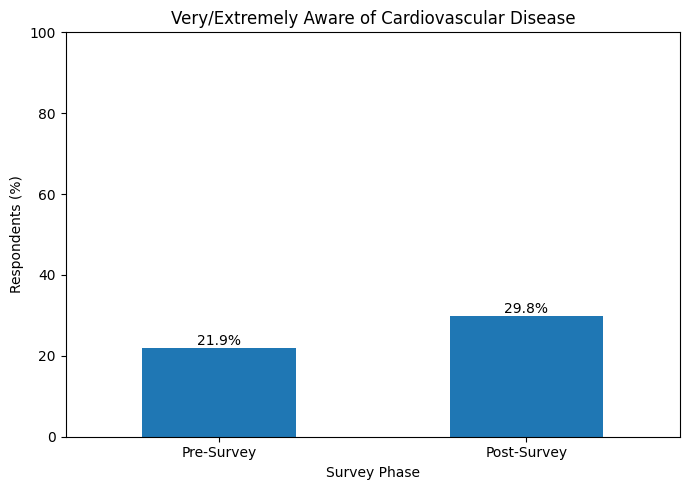

In [120]:
# Creating chart for cardiovascular awareness

awareness_chart = pd.Series({
    "Pre-Survey": pre_high_awareness,
    "Post-Survey": post_high_awareness
})

ax = awareness_chart.plot(
    kind="bar",
    figsize=(7, 5)
)

ax.set_title("Very/Extremely Aware of Cardiovascular Disease")
ax.set_xlabel("Survey Phase")
ax.set_ylabel("Respondents (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Visual 2 - Comfort Speaking to Doctor Pre vs. Post

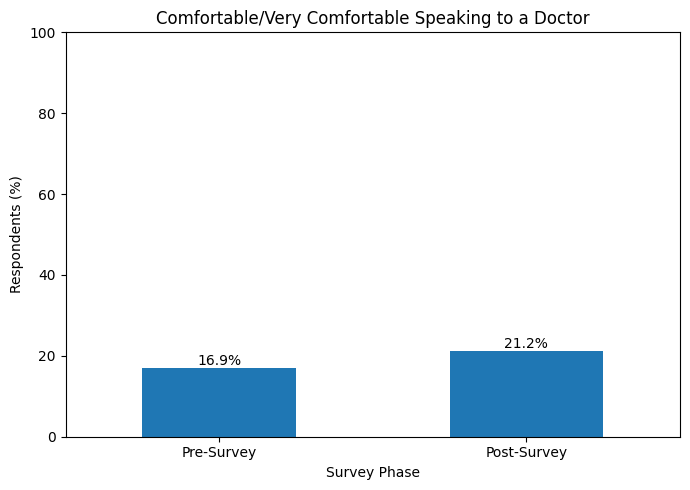

In [121]:
# Creating chart for comfort speaking to a doctor

comfort_chart = pd.Series({
    "Pre-Survey": pre_high_comfort,
    "Post-Survey": post_high_comfort
})

ax = comfort_chart.plot(
    kind="bar",
    figsize=(7, 5)
)

ax.set_title("Comfortable/Very Comfortable Speaking to a Doctor")
ax.set_xlabel("Survey Phase")
ax.set_ylabel("Respondents (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Visual 3 - Regular Health Monitoring Device Use Pre vs. Post

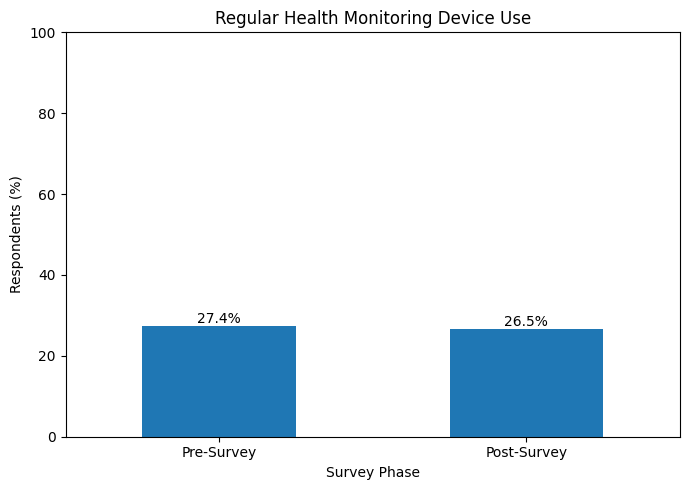

In [122]:
# Creating chart for regular health monitoring device use

device_chart = pd.Series({
    "Pre-Survey": pre_regular_device,
    "Post-Survey": post_regular_device
})

ax = device_chart.plot(
    kind="bar",
    figsize=(7, 5)
)

ax.set_title("Regular Health Monitoring Device Use")
ax.set_xlabel("Survey Phase")
ax.set_ylabel("Respondents (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Visual 4 - Post-Survey Cardiovascular Awareness by Age Group

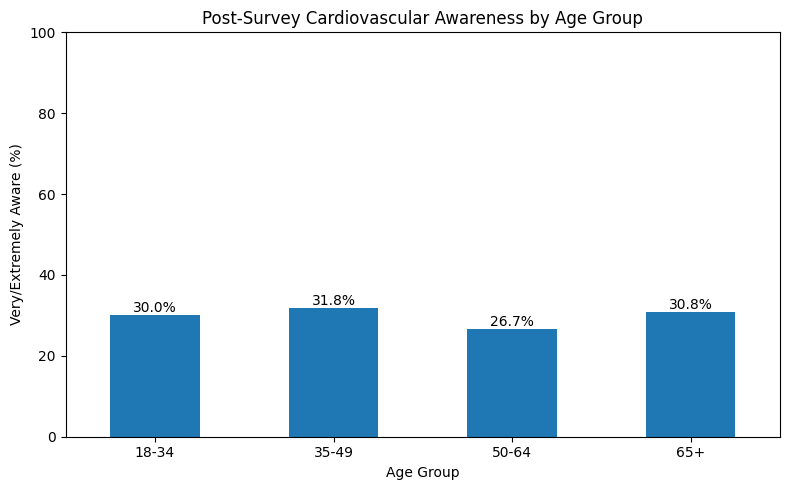

In [123]:
# Creating chart for post-survey cardiovascular awareness by age group

age_awareness_chart = {}

for age_group in ["18-34", "35-49", "50-64", "65+"]:

    age_post = post_survey[
        post_survey["Age Group"] == age_group
    ]

    age_percent = (
        age_post["Cardiovascular Disease Awareness"]
        .value_counts(normalize=True)
        .mul(100)
    )

    high_awareness = (
        age_percent.get("Very aware", 0)
        + age_percent.get("Extremely aware", 0)
    )

    age_awareness_chart[age_group] = high_awareness


age_awareness_chart = pd.Series(age_awareness_chart)

ax = age_awareness_chart.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_title("Post-Survey Cardiovascular Awareness by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Very/Extremely Aware (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Visual 5 - Post-Survey Program Satisfaction by Event

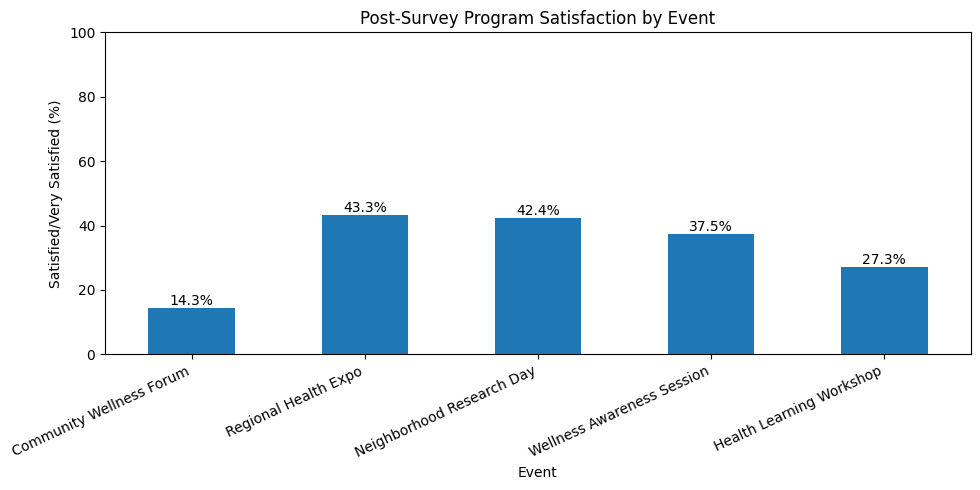

In [124]:
# Creating chart for post-survey program satisfaction by event

satisfaction_chart = {}

for event in post_survey["Event"].dropna().unique():

    event_data = post_survey[
        post_survey["Event"] == event
    ]

    satisfaction = (
        event_data["Program Satisfaction"]
        .dropna()
        .value_counts(normalize=True)
        .mul(100)
    )

    positive_satisfaction = (
        satisfaction.get("Satisfied", 0)
        + satisfaction.get("Very satisfied", 0)
    )

    satisfaction_chart[event] = positive_satisfaction


satisfaction_chart = pd.Series(satisfaction_chart)

ax = satisfaction_chart.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Post-Survey Program Satisfaction by Event")
ax.set_xlabel("Event")
ax.set_ylabel("Satisfied/Very Satisfied (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Key Event Findings

1. Cardiovascular awareness increased substantially after the events, with
   Very/Extremely aware responses increasing from 0.0% pre-survey to 77.7%
   post-survey (+77.7 percentage points).

2. Comfort speaking to a doctor about cardiovascular symptoms increased from
   0.0% Comfortable/Very comfortable pre-survey to 77.0% post-survey
   (+77.0 percentage points).

3. Regular health-monitoring device use remained relatively stable, increasing
   from 25.1% to 25.7% (+0.5 percentage points).

4. Post-survey cardiovascular awareness was consistently high across age groups,
   ranging from 75.9% among ages 18–34 to 80.0% among ages 35–49.

5. Positive program satisfaction varied by event. Seattle had the highest
   Satisfied/Very satisfied percentage at 45.5%, while Boston had the lowest
   at 25.0%.

### Interpretation Limitation

Pre- and post-survey records were analyzed as groups. The analysis does not
assume that individual pre-survey respondents were matched to individual
post-survey respondents.